In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors

# copied from /acadia-figure/supp-movie-x-THE-MODEL-cm229-checkpoint

In [4]:
# from __future__ import print_function
import pickle
import numpy as np
from ipywidgets import interact, interactive, fixed, interact_manual
# %matplotlib widget
import ipywidgets as widgets
import matplotlib.pyplot as plt
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import glob
from IPython.display import HTML
import imageio
import h5py
# %matplotlib inline
import matplotlib
matplotlib.rcParams['animation.embed_limit'] = 2**256
from matplotlib.ticker import MultipleLocator


In [38]:
prefix = '/mnt/staging/' # or 
mouse='cm229'

step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure6") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
raw_full_video_root = step_3_root+mouse+'/dc_full_front/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'
figure_config_root = str(PREPARES / "config") + "/"

CLS_root = str(PREPARES / "CLS") + "/"

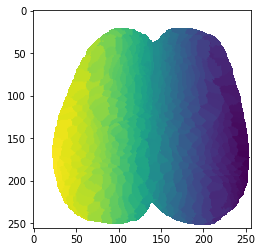

In [9]:
# sensory_ind.pop('nose')
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)

In [10]:
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse)

extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)

mega_dict_coherence = load_pickle(fetch_path_M1+'mega_dict_coherence_'+mouse)
M1_ind_from_coherence=mega_dict_coherence['mega_M1_ind_from_coherence']


In [12]:
palatte_behavior_fig7_dict = {'LFP_vel':'#e6782c',
                             'RFP_vel':'#2563b4',
                              'rot_smooth':'#24a464',
                              'face_pc':'#501d8a', 
                              'is_groom_smooth_ds':'#f5c0bf', 
                              'licking':'#ea4336'}

palatte_moseq_dict = {'is_running':'#01386A',
                     'is_integrated':'#2C6FBB',
                     'is_rest':'#F9BC08',
                     'is_licking_paw':'#EF4026',
                     'is_licking_spout':'#df2f2b',
                      'is_rise':'#028F1E',
                      'is_whisking':'#bf8fc9'
                     }

In [13]:
# load color
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
palatte_behavior_dict = load_pickle(figure_config_root+'palatte_behavior_dict')
col_list_palette = load_pickle(figure_config_root+'col_list_palette')
palatte_behavior_fig7_dict = load_pickle(figure_config_root+'palatte_behavior_fig7_dict')
palatte_moseq_dict = load_pickle(figure_config_root+'palatte_moseq_dict')

palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

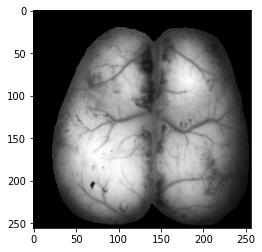

In [14]:
f3 = list(set(glob.glob(step_1_root+mouse+"/[2]/runB*.mat")))[0]
with h5py.File(f3,'r') as f_H: 
    m = f_H['m']
    
    # C = np.array(f_H['C']['blue'])
    # S = np.array(f_H['S']['blue'])[500:501,:
    # mask = np.array(f_H['mask'])
    # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
    # CS = np.dot(S,C).transpose()
    # blue = CS
    # blue = blue.reshape((256,256,-1))
    # ss=blue.shape;mask_tiled = np.tile(mask[:,:,np.newaxis],(1,1,ss[-1]))
    # blue = np.multiply(mask_tiled,blue)
    # blue=blue.transpose((1,0,2))
    
    C = np.array(f_H['C']['lime'])
    S = np.array(f_H['S']['lime'])[5500:5502,:]
    CS = np.dot(S,C).transpose()
    lime = CS
    lime = lime.reshape((256,256,-1))
#     ss=lime.shape;mask_tiled = np.tile(mask[:,:,np.newaxis],(1,1,ss[-1]))
#     lime = np.multiply(mask_tiled,lime)
    lime=lime.transpose((1,0,2))
          
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
    masked_brain = np.multiply(np.squeeze(lime[:,:,0]),mask)
    masked_brain=np.nan_to_num(masked_brain,0)
    plt.imshow(masked_brain,cmap='gray',vmin=100,vmax=2500)


In [15]:
time_dict = {'cm229_9_runC':[
                   [18806,18829]
                    ],
                   'cm229_9_runD':[
                   [3230,3270],
                       [5092,5136],
                       [5870,5905],
                       [7660,8380],
                       [8974,9142],
                       [10020,10080],
                       [10075,11120],
                       [13450,13520],
                       [15671,15750],
                       [17759,17777],
                       [18070,18080],
                       [18500,18530],
                       [18630,18650],
                       [20175,20210],
                       [21091,21140],
                       [34286,34315]
                   ],
                  'cm229_9_runE':[
                   [3440,3532],
                    [7399,7570],
                    [7599,7536],
                    [7760 , 7788],
                    [10060 , 10120],
                    [10500 , 10530],
                    [16360 , 16390],
                    [21672,21718],
                    [24769, 24799]],
                   'cm229_9_runF':[
                   [3344,3780],
                    [4050 , 4120],
                    [4505 ,4565],
                    [5768 , 6000],
                    [6465,6557],
                    [8095,8139],
                    [9182,9280],
                    [10205,10250],
                    [12830,12870],
                    [16469, 16500],
                    [18560,18601],
                    [24385,24443],
                    [28935,28980]],
                   'cm229_9_runG':[
                       [3543,3780],
                       [4458,4571],
                       [5798,5841]],
                    'cm229_9_runH':[
                       [3503,3866],
                        [3965,4157],
                        [4242 , 4262],
                        [5100 , 5138],
                        [5330, 5812],
                        [5880 , 6036],
                        [6390,6445],
                        [7038,7090],
                        [7132,7305],
                        [1332 , 7397],
                        [8220 ,8365],
                        [10642,10690],
                        [11490 , 11533],
                        [15780 ,15839]],
                   'cm229_9_runI':[
                        [1326,1390],
                        [1700 , 1740],
                        [2291 ,2530],
                        [3370,3996],
                        [4235 , 4299],
                        [4665 , 4720],
                        [4890 , 5254],
                        [6020 , 6211],
                        [6370,6591],
                        [6870,6858],
                        [7206,7531],
                        [7920,8028],
                        [8254,8605],
                        [8950,9002],
                        [10150 ,10224],
                        [11654,11950],
                        [12300,12343],
                        [12875,12940],
                        [13130,13529],
                        [15002, 15075],
                        [15775,15870],
                        [15934,15983],
                        [16330 ,16380],
                        [19260,19297],
                        [20665,20715],
                        [23811,23890],
                        [24075 , 24164],
                        [26995,27038],
                        [28143,28168],
                        [29695,29856],
                        [34580,34630]],
                   'cm229_9_runJ':[
                    [3602,4180],
                    [4866 ,4996],
                    [5074,5210],
                    [7136, 7186],
                    [7298,7336],
                    [9613,9630],
                    [9770,9808]]
}


# Prepare data first

which run :

In [16]:
fnames=list(set(glob.glob(step_1_root+"*229/9/*[C]*.mat")) )+list(set(glob.glob(step_1_root+"*229/9/*[D]*.mat")) )+list(set(glob.glob(step_1_root+"*229/4/*[B]*.mat")) )
fnames

['/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm229/9/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm229/9/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm229/4/runB_stim_1.mat']

In [12]:
# fnames=list(set(glob.glob(step_1_root+"*229/4/*[C]*.mat")) )
# fnames

In [17]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

In [18]:
all_bev_short_dict = {'LFP_vel':'FP(L) speed',
                     'RFP_vel':'FP(R) speed',
                     'mirrorRHP_vel_norm':'HP(R,mirror)',
                     'rot_smooth':'wheel speed',
                    'face_pc':'face pc',
                    'body_pc':'body pc',
                      'is_groom_smooth_ds':'in the box',
                      'licking':'licking spout',
                      'rise_RFP':'FP(R) vertical movements',
                      'rise_LFP':'FP(L) vertical movements',    
}

/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm229/9/runC_stim_1.mat
total_tpt 7975
/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm229/9/runD_stim_1.mat
total_tpt 7975
/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm229/4/runB_stim_1.mat
total_tpt 7975


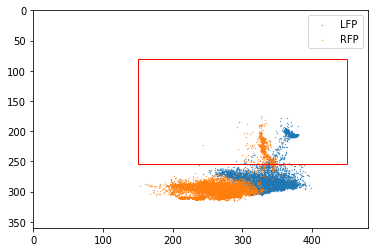

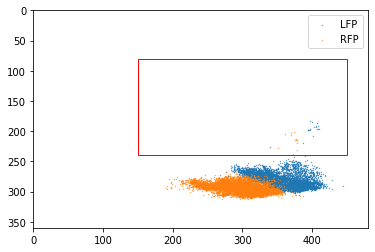

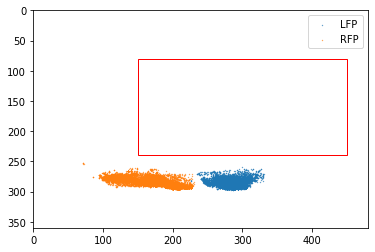

In [19]:
for beh in all_bev_short_dict:
    exec("concat_{} = np.empty(0)".format(beh))
concat_jrgeco = np.empty((256,256,0))


for i_fname, fname in enumerate(fnames):
    print(fname)
    split1=fname.split('_stim_1')
    run_name = split1[0]
    run = run_name[-4:]
    day=split1[0].split(mouse+'/')[1].split('/'+run)[0]
    mouse_day = mouse+'_'+day


    with h5py.File(fname,'r') as f_H: 

        m=f_H['m'] 
        C = np.array(f_H['C']['jrgeco'])
        S = np.array(f_H['S']['jrgeco'])

        # mask = np.array(f_H['mask'])
        # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
        nanidx = np.squeeze(np.array(m['nanidx']))==1
        CS = np.dot(S,C).transpose()
        jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
        jrgeco[:] = np.nan
        jrgeco[nanidx==True,:] = CS
        jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))[:,:,500:-503]
        total_tpt = jrgeco.shape[-1]
        print('total_tpt',total_tpt)
    #     C = np.array(f_H['C']['gcamp'])
    #     S = np.array(f_H['S']['gcamp'])

    #     mask = np.array(f_H['mask'])
    #     nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
    #     CS = np.dot(S,C).transpose()
    #     gcamp = np.zeros((len(nanidx),CS.shape[-1]))
    #     gcamp[:] = np.nan
    #     gcamp[nanidx==True,:] = CS
        # gcamp = gcamp.reshape((256,256,-1)).transpose((1,0,2))[:,:,500:-505]

        a=np.array(m['DAQ_ds'])
        rot = np.rad2deg(np.unwrap(a[:,-1]))
        rot = np.diff(rot)
        z = np.abs(stats.zscore(rot))
        threshold = 3
        outlier_ind = np.squeeze(np.where(z > 5))
        rot[outlier_ind]=np.nan
        rot_smooth = np.array(stats.zscore(np.squeeze(pd.DataFrame(rot).interpolate().rolling(20).mean().fillna(0))))
        rot_smooth = rot_smooth[500:-504]
        rot_2_detect = np.array(stats.zscore(np.squeeze(pd.DataFrame(rot).interpolate().rolling(20).std().rolling(20).mean().fillna(0))))
        rot_2_detect = rot_2_detect[500:-504]


        with(h5py.File(pjoin(step_3_root,
                                 mouse,day,run+'_cam_pc.mat'),'r')) as f_b:
            motionS = f_b['motionS']# this is the HDF5 reference
            motion_pc = {key: [] for key in list(motionS.keys())} 
            motion_pc_2detect = {key: [] for key in list(motionS.keys())} 
            for key in list(motionS.keys()):

                motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
                # (200,T)
                ss=motion_pc[key].shape
                tocut = ss[1]%4
                if tocut ==0:
                    motion_pc[key] = np.mean(motion_pc[key].values.reshape((ss[0],int(ss[1]/4),4)),axis=2)
                else:
                    motion_pc[key] = np.mean(motion_pc[key].iloc[:,:-tocut].values.reshape((ss[0],-1,4)),axis=2)

                motion_pc_2detect[key] = pd.DataFrame(motion_pc[key]).T.rolling(window=30).std().T                
                motion_pc[key] = pd.DataFrame(motion_pc[key]).T.rolling(window=5).std().T
                motion_pc_2detect[key]=motion_pc_2detect[key].iloc[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
                motion_pc[key]=motion_pc[key].iloc[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

        face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
        face_pc = stats.zscore(np.array(face_pc))
        body_pc = motion_pc['body'].iloc[:200,:].mean(axis=0)
        body_pc = stats.zscore(np.array(body_pc))
        body_pc_smooth = motion_pc_2detect['body'].iloc[:200,:].mean(axis=0)
        body_pc_smooth = stats.zscore(np.array(body_pc_smooth))    



        f_name_dlc = glob.glob(h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level

        paws_vel_df = pd.DataFrame()
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

        for i_bpt,bpt in enumerate(['LFP','RFP']):#make sure RFP comes out last
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel_smooth = pd.DataFrame(vel).rolling(40).std()
            vel = pd.DataFrame(vel).rolling(40).std()
            tocut = vel.shape[0]%4
            if tocut ==0:
                vel = np.mean(vel.values.reshape((-1,4)),axis=1)
                vel_smooth = np.mean(vel_smooth.values.reshape((-1,4)),axis=1)
            else:
                vel = np.mean(vel[:-tocut].values.reshape((-1,4)),axis=1)  
                vel_smooth = np.mean(vel_smooth[:-tocut].values.reshape((-1,4)),axis=1) 

            paws_vel_df[bpt] = stats.zscore(vel[500:-505])
            vel_ds = paws_vel_df[bpt].copy()
            vel_ds[vel_ds>3]=np.nan;
            paws_vel_df[bpt]=vel_ds
            paws_vel_df[bpt][0] = 0 # in case first frame is nan 
            paws_vel_df[bpt]=np.array(paws_vel_df[bpt].interpolate())

            vel_smooth = stats.zscore(vel_smooth[500:-505])
            vel_smooth[vel_smooth>3]=np.nan;
            vel_smooth=np.array(pd.DataFrame(vel_smooth).interpolate())


        LFP_vel = stats.zscore(np.array(paws_vel_df['LFP']))
        RFP_vel = stats.zscore(np.array(paws_vel_df['RFP']))
        vel_smooth = stats.zscore(vel_smooth)

        # is_groom plot # (480,360)
        import matplotlib.patches as patches

        x_top_left=80
        if run == 'runC':
            x_botton_right=255
        else:
            x_botton_right=240
        y_top_left=150
        y_botton_right=450

        out_h = int(x_botton_right - x_top_left)
        out_w = int(y_botton_right - y_top_left)
        y = x_top_left
        x = y_top_left

        fig,ax = plt.subplots(1)
        plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
        plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
        rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
        plt.ylim([0,360])
        plt.xlim([0,480])
        plt.legend()
        ax.add_patch(rect)
        plt.gca().invert_yaxis() 
        
        rise_LFP = new_df['LFP']['y'].copy().diff().rolling(5).std().rolling(3).mean()
        if tocut ==0:
            rise_LFP = np.mean(rise_LFP.values.reshape((-1,4)),axis=1) #(11980,)
        else:
            rise_LFP = np.mean(rise_LFP[:-tocut].values.reshape((-1,4)),axis=1) #(11980,)
        rise_LFP = rise_LFP[500:-505] 

        rise_RFP = new_df['RFP']['y'].copy().diff().rolling(5).std().rolling(3).mean()
        if tocut ==0:
            rise_RFP = np.mean(rise_RFP.values.reshape((-1,4)),axis=1) #(11980,)
        else:
            rise_RFP = np.mean(rise_RFP[:-tocut].values.reshape((-1,4)),axis=1) #(11980,)
        rise_RFP = rise_RFP[500:-505] 

        is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
        is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
        is_groom = np.logical_or(is_groom_LFP,is_groom_RFP)
        # is_in_box = np.logical_or(is_groom_LFP,is_groom_RFP)
        
        is_groom_smooth = is_groom.rolling(30).mean()
        if tocut ==0:
            is_groom_smooth_ds = np.mean(is_groom_smooth.values.reshape((-1,4)),axis=1)
        else:
            is_groom_smooth_ds = np.mean(is_groom_smooth[:-tocut].values.reshape((-1,4)),axis=1) #(11980,)
        is_groom_smooth_ds = is_groom_smooth_ds[500:-505]



        f_name_dlc = glob.glob(mirror_h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df_2 = Dataframe[scorer] # de-level

        paws_vel_df = pd.DataFrame()
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

        for i_bpt,bpt in enumerate(['LFP','RFP','LHP','RHP']):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df_2[bpt]['x'].values.flatten(), new_df_2[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel).rolling(40).std()
            tocut = vel.shape[0]%4
            if tocut ==0:
                vel = np.mean(vel.values.reshape((-1,4)),axis=1)
            else:
                vel = np.mean(vel[:-tocut].values.reshape((-1,4)),axis=1)   
            paws_vel_df[bpt] = vel[500:-505]

        mirrorLFP_vel = np.array(paws_vel_df['LFP'])
        mirrorRFP_vel = np.array(paws_vel_df['RFP'])
        mirrorLHP_vel = np.array(paws_vel_df['LHP'])
        mirrorRHP_vel = np.array(paws_vel_df['RHP'])

        mirrorLFP_vel_norm = stats.zscore(mirrorLFP_vel)
        mirrorRFP_vel_norm = stats.zscore(mirrorRFP_vel)
        mirrorLHP_vel_norm = stats.zscore(mirrorLHP_vel)
        mirrorRHP_vel_norm = stats.zscore(mirrorRHP_vel)

        try:
            start_stop_ind=pd.DataFrame(time_dict[mouse_day+'_'+run])
            start_stop_ind=start_stop_ind/4-500
            start_stop_ind=start_stop_ind.round().astype('int')

            licking =np.zeros(total_tpt);
            for i_range in range(len(start_stop_ind)):
                licking[start_stop_ind.iloc[i_range,0]:start_stop_ind.iloc[i_range,1]]=1
        except:
            licking = np.zeros(total_tpt)
        
        # CONCAT ALL RUNS HERE
        for beh in all_bev_short_dict:
            exec("concat_{} = np.append(concat_{},{},axis=0)".format(beh,beh,beh))
                 
        concat_jrgeco = np.append(concat_jrgeco,jrgeco,axis=2)

In [20]:
concat_jrgeco.shape

(256, 256, 23925)

In [21]:
for beh in all_bev_short_dict:
    exec("print(beh,concat_{}.shape)".format(beh))

LFP_vel (23925,)
RFP_vel (23925,)
mirrorRHP_vel_norm (23925,)
rot_smooth (23925,)
face_pc (23925,)
body_pc (23925,)
is_groom_smooth_ds (23925,)
licking (23925,)
rise_RFP (23925,)
rise_LFP (23925,)


In [23]:
# load midline
with h5py.File(figure_config_root+'mask_midline_v2_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
mask_midline_array = np.repeat(mask_midline[:,:,np.newaxis],repeats=concat_jrgeco.shape[-1],axis=2)
concat_jrgeco = np.multiply(concat_jrgeco,mask_midline_array)



In [24]:
H = getH(concat_jrgeco,IDX_sorted)

/home/wx2203/Weihao/code_locker/common_functions/f2_utils.py:17: RuntimeWarning: Mean of empty slice
  H[i_H,:]=np.nanmean(data_reshape[temp==True,:],axis=0)


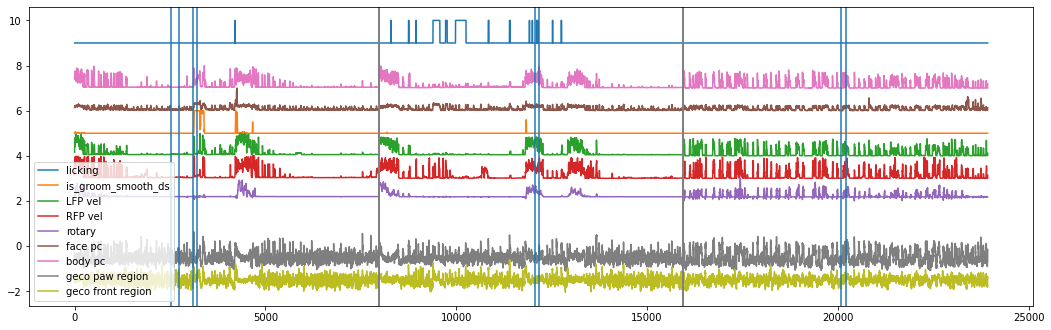

In [25]:
plt.figure(figsize=(18,5.5))

plt.plot(concat_licking+9,label='licking')
plt.plot(concat_is_groom_smooth_ds+5,label='is_groom_smooth_ds')
plt.plot(normalize(concat_LFP_vel)+4,label='LFP vel')
plt.plot(normalize(concat_RFP_vel)+3,label='RFP vel')
plt.plot(normalize(concat_rot_smooth)+2,label='rotary')
# plt.plot(normalize(concat_vel_smooth)+1,label='vel_smooth 2 detect')
plt.plot(normalize(concat_face_pc)+6,label='face pc')
plt.plot(normalize(concat_body_pc)+7,label='body pc')
# plt.plot(normalize(concat_body_pc_smooth)+8,label='body pc smooth')

# for i in range(len(start_stop_ind)):
#     plt.vlines(range(start_stop_ind.iloc[i,0],start_stop_ind.iloc[i,0]+60),
#                -3.2, 9,linewidth = 0.2,color='y',alpha=0.3)
# plt.vlines(range(start_stop_ind.iloc[0,0],start_stop_ind.iloc[0,0]+60),
#                -0.05, 0.01,linewidth = 1,color='y',alpha=0.3,label='running bouts')
# plt.title(mouse_day+'_'+run_name)
plt.plot(H[408,:]*8-0.5,label='geco paw region')
plt.plot(H[338,:]*8-1.5,label='geco front region')
plt.legend(fontsize = 10)
plt.axvline(total_tpt,linewidth=2,color='gray')
plt.axvline(total_tpt*2,linewidth=2,color='gray')

plt.axvline(total_tpt*2+4181-40)
plt.axvline(total_tpt*2+4191+80)

plt.axvline(total_tpt+4080)
plt.axvline(total_tpt+4190)

plt.axvline(2529)
plt.axvline(2733)

plt.axvline(3105)
plt.axvline(3200)

In [26]:
dict_select_time_range = {
    'rest':[(2529,2733)],
         'integrated':[(3105,3200),3124,3130],
         'lick':[(total_tpt+4080,total_tpt+4190),total_tpt+4018],
         'run':[(total_tpt*2+4181-40,total_tpt*2+4181+100),total_tpt*2+4181], 
}

dict_select_baseline_range = {
    'rest':range(0,2733-2529), # entire duration as baseline
         'integrated':range(0,10), # first 10 frames
         'lick':range(66,74),
         'run':range(29,39),
}

# dict_webcam_img = {choice_syllable:[] for choice_syllable in dict_select_time_range.keys()}

# all_brokens = [dict_select_time_range[
#     choice_syllable][0] for choice_syllable in dict_select_time_range.keys()]
# all_brokens = [(t_ax_2show[broken[0]],t_ax_2show[broken[1]]) for broken in all_brokens]

In [27]:
t_empty = 100
for beh in all_bev_short_dict:
    exec("cut_{} = np.empty(0)".format(beh))
cut_jrgeco = np.empty((256,256,0))
empty_jrgeco = np.zeros((256,256,t_empty))
cut_time_record = np.empty(0)


for i_choice_syllable, choice_syllable in enumerate(['rest','run','lick','integrated']):
    
    # slice them off the concat
    time_index = dict_select_time_range[choice_syllable][0]
    slice_here  = concat_jrgeco[:,:,time_index[0]:time_index[1]]
    # re-baseline neural activity
    slice_here = slice_here - np.mean(slice_here[:,:,
                            dict_select_baseline_range[choice_syllable]],-1)[:,:,np.newaxis]
    # append
    cut_jrgeco = np.append(cut_jrgeco,slice_here,axis=2)
    cut_time_record = np.append(cut_time_record,np.ones(slice_here.shape[-1]),axis=0)
    cut_jrgeco = np.append(cut_jrgeco,empty_jrgeco,axis=2)
    cut_time_record = np.append(cut_time_record,np.zeros(t_empty),axis=0)
    
    # do the 
    for beh in all_bev_short_dict:
        exec("cut_{} = np.append(cut_{},concat_{}[time_index[0]:time_index[1]],axis=0)".format(beh,beh,beh))
        exec("cut_{} = np.append(cut_{},np.zeros(t_empty),axis=0)".format(beh,beh))
    
H = getH(cut_jrgeco,IDX_sorted)    

In [28]:
t_ax_2show = np.divide(range(cut_jrgeco.shape[-1]),15) 
time_stamp = np.linspace(0,cut_jrgeco.shape[-1]/15,cut_jrgeco.shape[-1])

dict_webcam_img = {choice_syllable:[] for choice_syllable in dict_select_time_range.keys()}


all_brokens = start_stop(cut_time_record>0.1,True)
all_brokens = [(t_ax_2show[broken[0]],t_ax_2show[broken[1]-1]) for broken in all_brokens]



In [29]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')
seed_ROI_xy = dict_seed_ROI_xy_mice['cm229']

In [31]:
choice_body_part_dict = {0:'RFP_S1',1:'RFP_M1',2:'RFP_M2',3:'RM_S1',
                         4:'RM_M1',5:'RM_M2',}

choice_dict = {0:sensory_ind['RFP'],1:322,
               2:M2_ind['RFP'],3:sensory_ind['RM'],
               4:M1_ind_from_coherence['RM'],5:M2_ind['RM']}

# IMPORTANT: 
jrgeco2plot={}
for i_bdp in range(6):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    jrgeco2plot[bdp] = H[ind,:]

# more accurate M2 ROIs location
# IMPORTANT: 
list_choice_M2 = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
jrgeco2plot_M2={};node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    small_roi_tcs = np.nanmean(np.nanmean(
cut_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot_M2[bdp] = small_roi_tcs

    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])


        
# replace M2 tcs with more accurate ones
jrgeco2plot['RFP_M2']=jrgeco2plot_M2['RFP']
jrgeco2plot['RM_M2']=jrgeco2plot_M2['RM']

choice_behaviors = ['LFP_vel', 'RFP_vel', 'rot_smooth',
                    'face_pc', 'is_groom_smooth_ds', 'licking']
behaviors = {}
for i_bev, behavior in enumerate(choice_behaviors):
    exec("behaviors[behavior] = cut_{}".format(behavior))

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:26: RuntimeWarning: Mean of empty slice


In [32]:
palatte_dict['RM_M2']='#bf8fc9'
palatte_dict['RM_M1']='lightseagreen'
palatte_dict['RFP_M2']='#6dae96'
# palatte_dict['RFP_M1']=palatte_dict['RHP']
palatte_dict['RM_S1']=palatte_dict['RM']
palatte_dict['RFP_S1']=palatte_dict['RFP']

In [33]:
#behavior segmentation
big_df = behaviors.copy()
# big_df['face_pc'] = np.append(big_df['face_pc'],0) # prevent error

is_rise = cut_rise_LFP+cut_rise_RFP> 24
is_rise_strict = cut_rise_LFP+cut_rise_RFP> 18

is_running = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                          big_df['LFP_vel']>0.1),big_df['rot_smooth']>0.05),~is_rise)

is_integrated = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.2, 
                          big_df['LFP_vel']>0.1),big_df['rot_smooth']<0.1),~is_rise_strict)


is_whisking = np.logical_and(big_df['face_pc']>0.4,big_df['is_groom_smooth_ds']<0.05)

is_licking_paw = np.logical_and(np.logical_and(np.logical_and(big_df['face_pc']>0.4, 
                          big_df['LFP_vel']<0.1),big_df['RFP_vel']<0.1),big_df['is_groom_smooth_ds']>0.05)


is_rest = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                          big_df['LFP_vel']<0.1),big_df['rot_smooth']<0.1),big_df['face_pc']<0.1)

is_licking_spout = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.05, 
                          big_df['licking']>0.1),~is_rise),~is_licking_paw)
dict_moseq={'is_whisking':is_whisking,'is_rise':is_rise,'is_running':is_running,
       'is_integrated':is_integrated,'is_rest':is_rest,'is_licking_spout':is_licking_spout,'is_licking_paw':is_licking_paw}

# component 1: broken axis plot

In [34]:
for i, moseq in enumerate(dict_moseq):
    dict_moseq[moseq][cut_time_record==0]=False


In [114]:
# axvlines = [330, 447, 504,12006, 12113, 12146]

In [35]:
dict_select_time_range

{'rest': [(2529, 2733)],
 'integrated': [(3105, 3200), 3124, 3130],
 'lick': [(12055, 12165), 11993],
 'run': [(20091, 20231), 20131]}

In [36]:
from brokenaxes import brokenaxes

# replace TC with NNLS

In [37]:
all_bdps_list_S1 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RT','LFP', 'LHP',  'LW', 'LM', 'LN','LT']
all_bdps_list_M2 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RV','LFP', 'LHP',  'LW', 'LM', 'LN','LV']
all_bdps_list_M1 = [ 'RFP', 'RHP', 'LFP', 'LHP']
all_bdps_extra = ['RALM','LALM', 'RV', 'LV','RRSP','LRSP','RFP_M1_extra','LFP_M1_extra', 
                 'RholeMOp','LholeMOp',
                 'Rposterior','Lposterior'
                 ]
all_bdps_S1 = [bdp+'_S1' for bdp in all_bdps_list_S1]
all_bdps_M2 = [bdp+'_M2' for bdp in all_bdps_list_M2]
all_bdps_M1 = [bdp+'_M1' for bdp in all_bdps_list_M1]

all_bdps = all_bdps_extra + all_bdps_M2 + all_bdps_S1 + all_bdps_M1

In [40]:

save_dict = load_pickle(CLS_root+'M2S1M1_NNLS_spatial_'+mouse)
all_bdps_w_order = save_dict['all_bdps_w_order']
full_M = save_dict['full_M']
# mask_M2 = save_dict['mask_M2']

mask = cut_jrgeco[:,:,0]>-1
mask = mask.astype(float)
mask[mask==0]=np.nan
mask_reshape = mask.reshape((256*256))

W_S1M2M1 = full_M[mask_reshape==1,:]

# W_masked_S1M2M1 = np.zeros((256*256,W_S1M2M1.shape[-1]));W_masked_S1M2M1[:]=np.nan
# W_masked_S1M2M1[mask_reshape==1,:] = W_S1M2M1
# W_masked_S1M2M1 = W_masked_S1M2M1.reshape((256,256,-1))

# add M2 ones
W_S1M2M1_M2 = []
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    W_S1M2M1_M2.append(W_S1M2M1[:,ind_in_list])
W_S1M2M1_M2_sum = np.clip(np.sum(np.stack(W_S1M2M1_M2,0),0), 0, 1)
W_S1M2M1 = np.append(W_S1M2M1,W_S1M2M1_M2_sum[:,np.newaxis],axis=1)
# add cortical ones
W_S1M2M1 = np.append(W_S1M2M1,np.ones((len(W_S1M2M1_M2_sum),1)),axis=1)

W_masked = np.zeros((256*256,W_S1M2M1.shape[-1]));W_masked[:]=np.nan
W_masked[mask_reshape==1,:] = W_S1M2M1
W_masked = W_masked.reshape((256,256,-1))


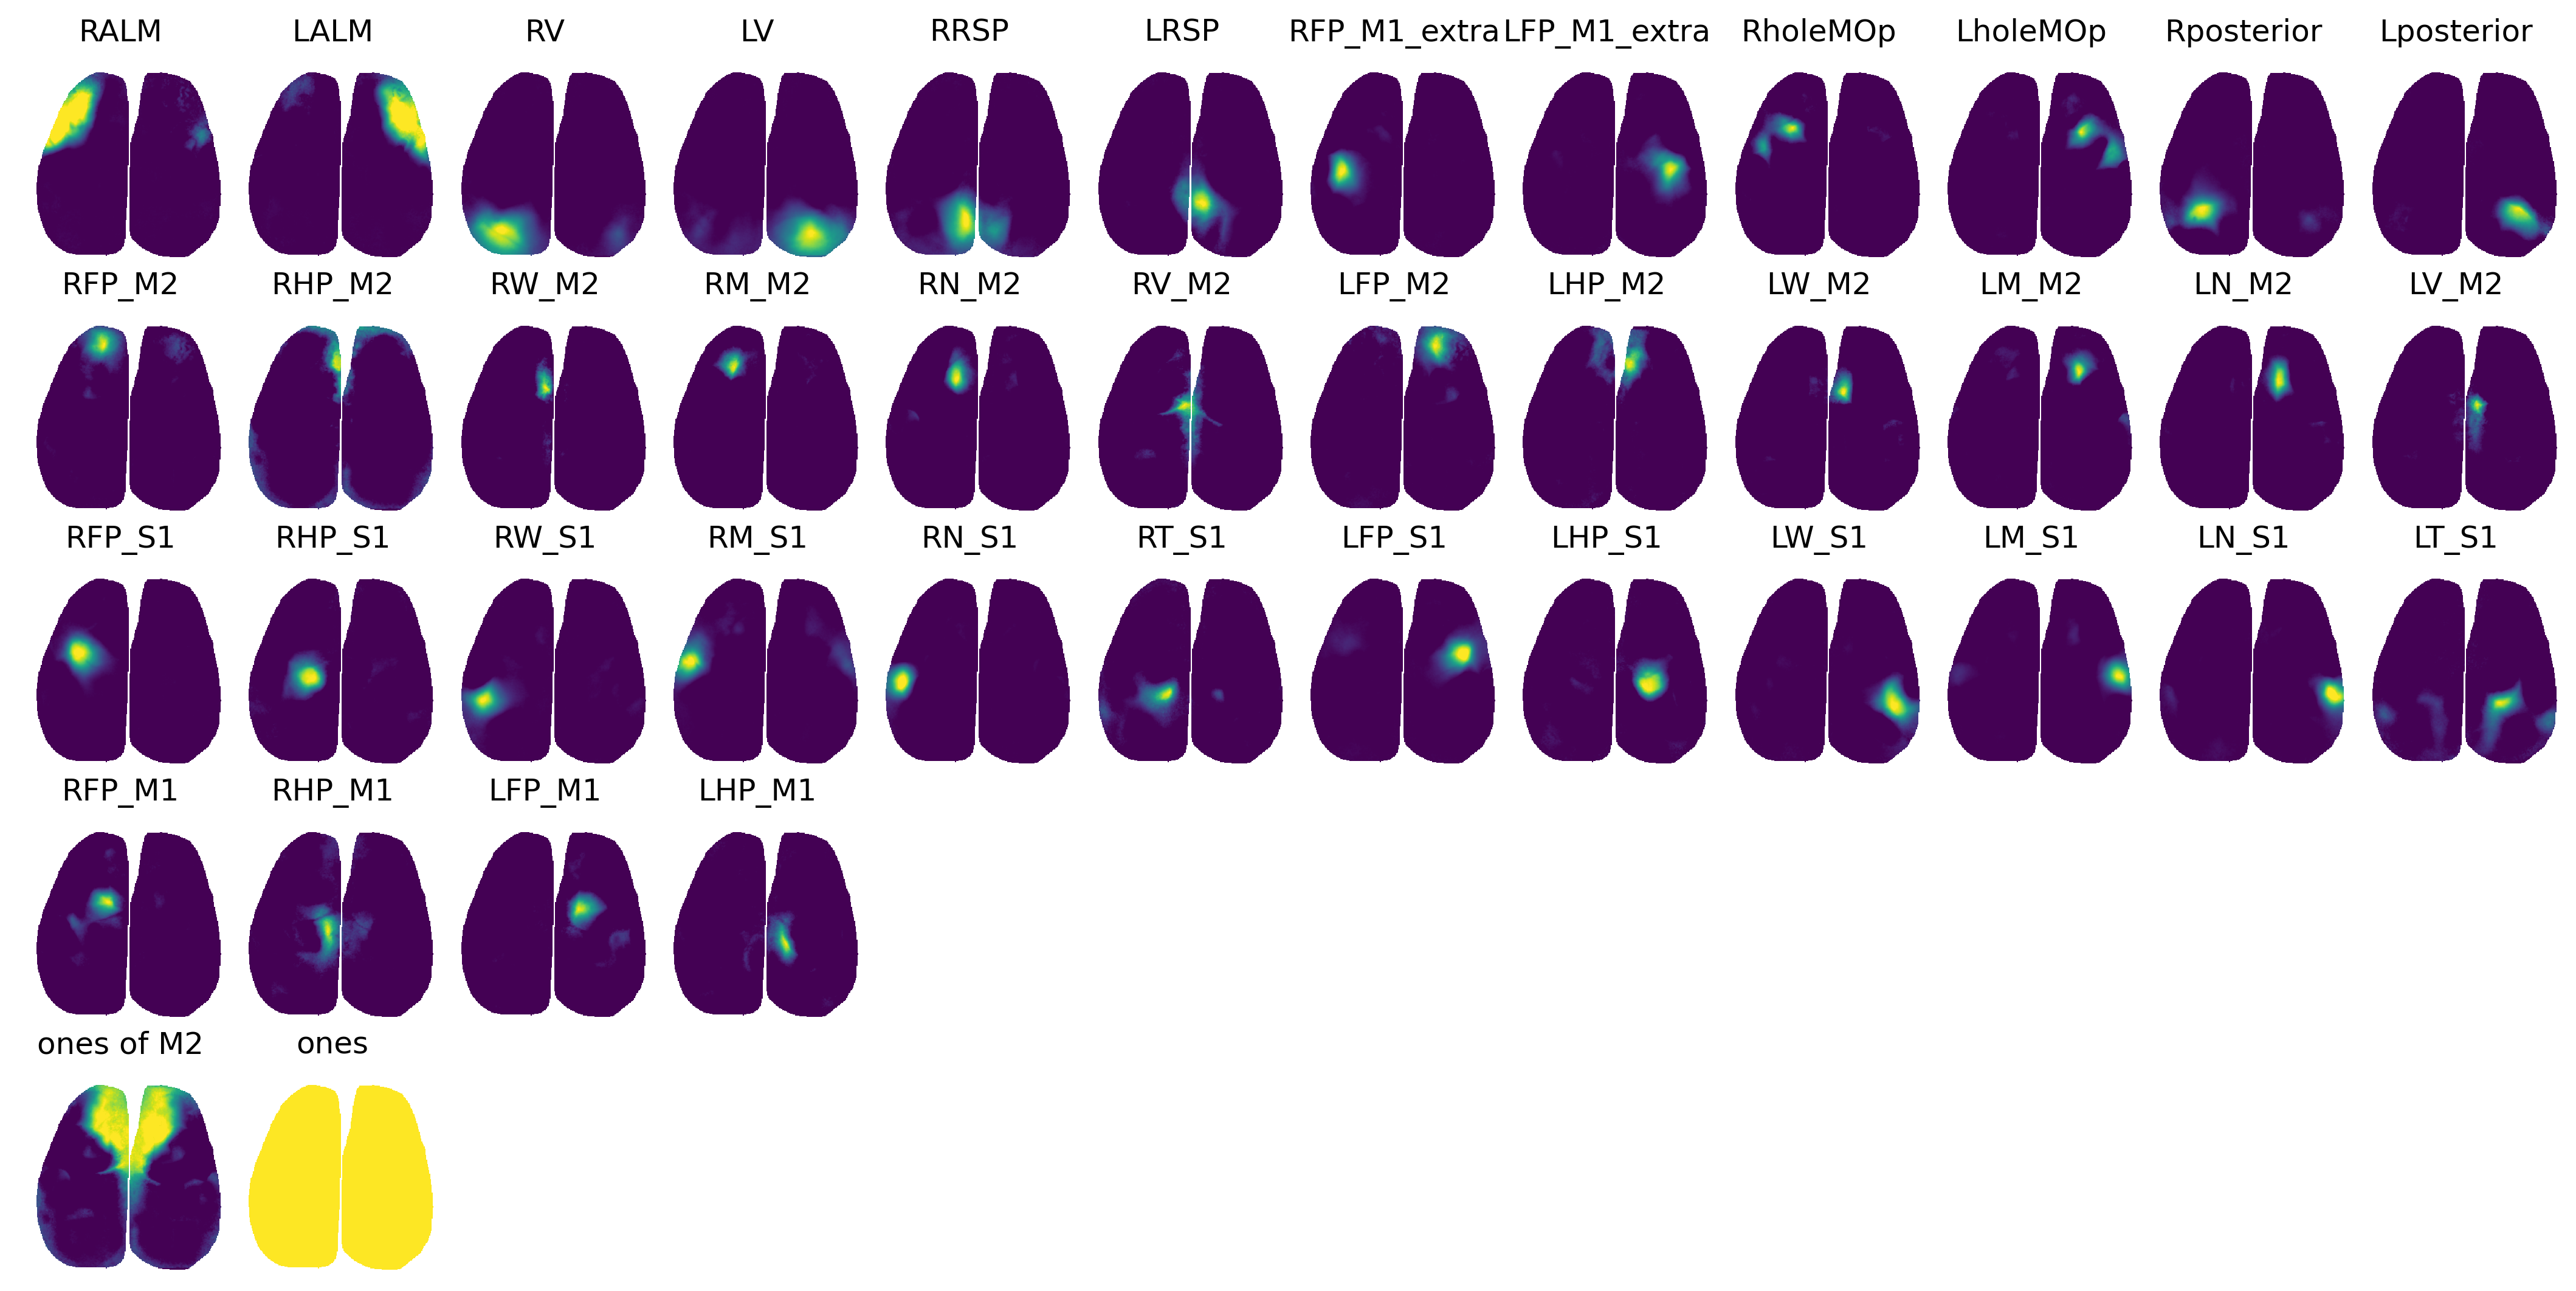

In [43]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)):
    exec("ax{} = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+12:y_offset+17,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)):
    exec("ax{} = fig.add_subplot(gs[y_offset+18:y_offset+23,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
x_start = x_offset
x_stop = x_start+5
for i_ax in range(len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1),len(all_bdps_M2)+len(all_bdps_extra)+len(all_bdps_S1)+len(all_bdps_M1)+2):
    exec("ax{} = fig.add_subplot(gs[y_offset+24:y_offset+29,x_start:x_stop])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
    
##########################################
##########################################
for i_key,key in enumerate(all_bdps_extra):
    ind_in_list = all_bdps.index(key)
    W_masked_2show = W_masked[:,:,ind_in_list]        
    exec("ax{}.imshow(W_masked_2show,vmin=0,vmax=1)".format(i_key))
    exec("ax{}.set_title(key)".format(i_key))
    # plt.axis('off')
for i_key,key in enumerate(all_bdps_M2):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))
for i_key,key in enumerate(all_bdps_S1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))
for i_key,key in enumerate(all_bdps_M1):
    ind_in_list = all_bdps.index(key)
    i_entry = i_key+len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)
    exec("ax{}.imshow(W_masked[:,:,ind_in_list],vmin=0,vmax=1)".format(i_entry))
    exec("ax{}.set_title(key)".format(i_entry))

# plot median
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)
exec("ax{}.imshow(W_masked[:,:,-2],vmin=0,vmax=1)".format(i_entry))
exec("ax{}.set_title('ones of M2')".format(i_entry))
 
# plot 1
i_entry = len(all_bdps_extra)+len(all_bdps_M2)+len(all_bdps_S1)+len(all_bdps_M1)+1
exec("ax{}.imshow(W_masked[:,:,-1],vmin=0,vmax=0.1)".format(i_entry))
exec("ax{}.set_title('ones')".format(i_entry))

for i_ax in range(50):
    try:
        exec("ax{}.axis('off')".format(i_ax))
    except:
        continue

In [45]:
mouse_id = mouse
   
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse_id)
sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse_id)

extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse_id)
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse_id)

# sensory_ind['RV']=extra_extra_ind['RV']
# sensory_ind['LV']=extra_extra_ind['LV']
sensory_ind['LV']=106
sensory_ind['RV']=415

mega_dict_coherence = load_pickle(fetch_path_M1+'mega_dict_coherence_'+mouse)
M1_ind_from_coherence=mega_dict_coherence['mega_M1_ind_from_coherence']
M2_ind_from_coherence=mega_dict_coherence['mega_M2_ind_from_coherence']

sensory_ind['LW']=54
sensory_ind['RW']=464
sensory_ind['RRSP']= 310 # cm229
sensory_ind['LRSP']= 211 # cm229
sensory_ind['LALM']=extra_ind['ALM']
sensory_ind['RALM']=447
sensory_ind['RFP_M1_extra']=440 # cm229
sensory_ind['LFP_M1_extra']=79 # cm229
sensory_ind['RholeMOp']=381 # cm229
sensory_ind['LholeMOp']=119 # cm229
sensory_ind['RT']=sensory_ind['tail'] # cm229
sensory_ind['LT']=139
sensory_ind['Rposterior']=418 # cm229
sensory_ind['Lposterior']=80 # cm229

In [46]:
cut_H = H
TCs_matrix = np.empty((0,cut_H.shape[1]))

for i_key,key in enumerate(all_bdps_extra):
    TCs_matrix = np.append(TCs_matrix,
                           cut_H[sensory_ind[key],np.newaxis,:],
                           axis=0)
    
for i_key,key in enumerate(all_bdps_M2):
    bdp = key.split('_M2')[0]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    small_roi_tcs = np.nanmean(np.nanmean(
cut_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    TCs_matrix = np.append(TCs_matrix,
                           small_roi_tcs[np.newaxis,:],
                           axis=0)

for i_key,key in enumerate(all_bdps_S1):
    bdp = key.split('_S1')[0]
    TCs_matrix = np.append(TCs_matrix,
                           cut_H[sensory_ind[bdp],np.newaxis,:],
                           axis=0)
    
for i_key,key in enumerate(all_bdps_M1):
    bdp = key.split('_M1')[0]
    TCs_matrix = np.append(TCs_matrix,
                           cut_H[M1_ind_from_coherence[bdp],np.newaxis,:],
                           axis=0)
    

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: Mean of empty slice
  app.launch_new_instance()


In [47]:
# append MEAN tc 
index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
TCs_matrix=np.append(TCs_matrix,np.mean(TCs_matrix[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
# append 1 tc 
TCs_matrix = np.append(TCs_matrix,np.ones((1,TCs_matrix.shape[1])),axis=0)



# solve H from W

In [48]:
from scipy.optimize import minimize
from scipy.sparse import csr_matrix
def nnls_optimization_with_constraints(A, b,x_init,constraints):
    """
    Solves the Non-Negative Least Squares (NNLS) problem using constrained optimization.

    Parameters:
    A (numpy.ndarray or scipy.sparse.csr_matrix): The input matrix.
    b (numpy.ndarray): The input vector.

    Returns:
    numpy.ndarray: The solution vector x.
    """
    # Check if A is sparse and convert to csr_matrix if it is not
    if not isinstance(A, csr_matrix):
        A = csr_matrix(A)

    # Objective function: 0.5 * ||Ax - b||^2
    def objective(x):
        residual = A.dot(x) - b
        return 0.5 * np.linalg.norm(residual)**2

    # Gradient of the objective function
    def objective_jac(x):
        return A.T.dot(A.dot(x) - b)

    # Initial guess (zeros)
    x0 = x_init #np.zeros(A.shape[1])
    # x0 = np.zeros(A.shape[1])

    
    result = minimize(objective, x0, method='SLSQP',constraints=constraints,jac=objective_jac, options={'disp': False})

    return result.x

index_M2s = [idx for idx, s in enumerate(all_bdps) if '_M2' in s]
  
def return_constraints(H_ROI,median_here,index_M2s,k):
    # Define the constraints
    constraints = []
    for i_M2 in index_M2s:
        constraints.append({
            'type': 'eq',
            'fun': lambda x, i_M2=i_M2: x[i_M2] - (H_ROI[i_M2] - x[-2])
        })
    # constraints.append({'type': 'eq', 'fun': lambda x: x[-2] - k*median_here})  
    constraints.append({'type': 'ineq', 'fun': lambda x: 0.001 - (np.abs(x[-2] - k*median_here))})  

    return constraints

In [49]:
cut_full_jrgeco_reshape=cut_jrgeco.copy().reshape((256*256,-1))[mask_reshape==1]

H_ROI = TCs_matrix
# H_ROI=np.append(H_ROI,np.median(H_ROI[index_M2s,:],axis=0)[np.newaxis,:],axis=0)
median_M2_tc = np.mean(H_ROI[index_M2s,:],0)

start = time.time()
temp = Parallel(n_jobs=20)(delayed(nnls_optimization_with_constraints)(
    W_S1M2M1, 
    cut_full_jrgeco_reshape[:,i_t],H_ROI[:,i_t],return_constraints(H_ROI[:,i_t],median_M2_tc[i_t],index_M2s,0.45)) for i_t in range(cut_full_jrgeco_reshape.shape[1]))
H_fitted = np.vstack(temp).T
end = time.time()
print(end - start)


56.33803367614746


In [50]:
new_time_range = start_stop(cut_time_record>0.1,True)

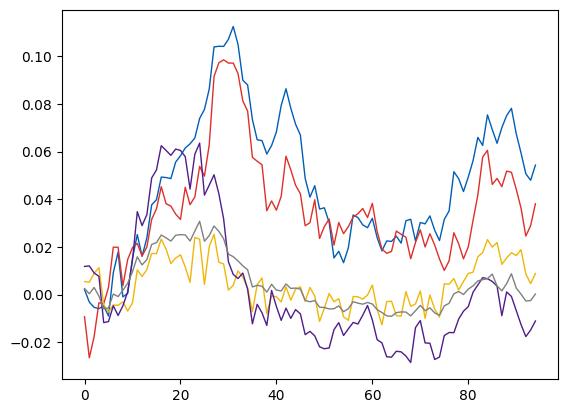

In [51]:
select_beh_2_show = 'integrated'
time_range_here = new_time_range[-1]
select_bdp = 'RFP'

mean_tc = H_fitted[-2,:]

for ii,bdp in enumerate(['RFP','RM','RHP','RW']):
    offset_here = 0
    ind_in_list = all_bdps_w_order.index(bdp+'_M2')
    to_plot_tc = H_fitted[ind_in_list,:]*2
    plt.plot(to_plot_tc[time_range_here[0]:time_range_here[1]]+offset_here,color=palatte_dict[bdp],linewidth=1)
plt.plot(mean_tc[time_range_here[0]:time_range_here[1]]+offset_here,color='gray',linewidth=1)


In [54]:
jrgeco2plot_NNLS={}
for bdp in ['RFP','RHP']:
    for area in ['S1','M1','M2']:
        bdp_area = bdp+'_'+area
        ind_in_list = all_bdps_w_order.index(bdp_area)
        jrgeco2plot_NNLS[bdp_area] = H_fitted[ind_in_list,:]

for bdp in ['RM','RW']:
    for area in ['S1','M2']:
        bdp_area = bdp+'_'+area
        ind_in_list = all_bdps_w_order.index(bdp_area)
        jrgeco2plot_NNLS[bdp_area] = H_fitted[ind_in_list,:]
        
for i_bdp,bdp_name in enumerate([ 'RALM','RV','RRSP','RholeMOp','globalM2']):
    if bdp_name == 'globalM2':
        jrgeco2plot_NNLS[bdp_name+'_extra'] = H_fitted[-2,:]
    else:
        ind_in_list = all_bdps_w_order.index(bdp_name)
        jrgeco2plot_NNLS[bdp_name+'_extra'] = H_fitted[ind_in_list,:]

In [56]:
ind_collection={}
# select time points to plot behavior and stuffs
ind_collection['run'] = [new_time_range[1][0]+41]
ind_collection['lick'] = [new_time_range[2][0]+47] # first licking event
ind_collection['lick'] = [new_time_range[2][0]+78]
ind_collection['integrated'] = [new_time_range[3][0]+25, new_time_range[3][0]+30]


In [61]:
palatte_dict['RHP_S1']=palatte_dict['RHP']
palatte_dict['RHP_M1']='#E0D70D'
palatte_dict['RHP_M2']='#B6D438'

palatte_dict['RW_S1']=palatte_dict['RW']
# palatte_dict['RW_M1']=palatte_dict['LW']
palatte_dict['RW_M2']='#C11F8C'

palatte_dict['RFP_S1']=palatte_dict['RFP']
palatte_dict['RFP_M1']=palatte_dict['LFP']
palatte_dict['RFP_M2']='#33A6C2'#'#069FC2'

palatte_dict['RM_S1']=palatte_dict['RM']
# palatte_dict['RM_M1']='#FFA67F'
palatte_dict['RM_M2']='#D25A8E'

palatte_dict['median_allM2'] = 'gray'
palatte_dict['globalM2_extra'] = palatte_dict['median_allM2']


palatte_dict['RALM_extra'] = palatte_dict['ALM']
palatte_dict['LALM'] = 'bisque'
palatte_dict['RRSP_extra'] = palatte_dict['RSP']
palatte_dict['LRSP'] = 'sandybrown'
palatte_dict['RFP_M1_extra'] = 'tab:olive'
palatte_dict['LFP_M1_extra'] = 'tab:cyan'

palatte_dict['RholeMOp_extra'] = '#ff964f' #pastel orange
palatte_dict['LholeMOp'] = '#ff964f' #pastel orange

palatte_dict['RT'] = 'darkseagreen'
palatte_dict['LT'] = 'olivedrab'

palatte_dict['Rposterior'] = 'palegreen'
palatte_dict['Lposterior'] = 'greenyellow'

palatte_dict['RV_extra'] = palatte_dict['RV']

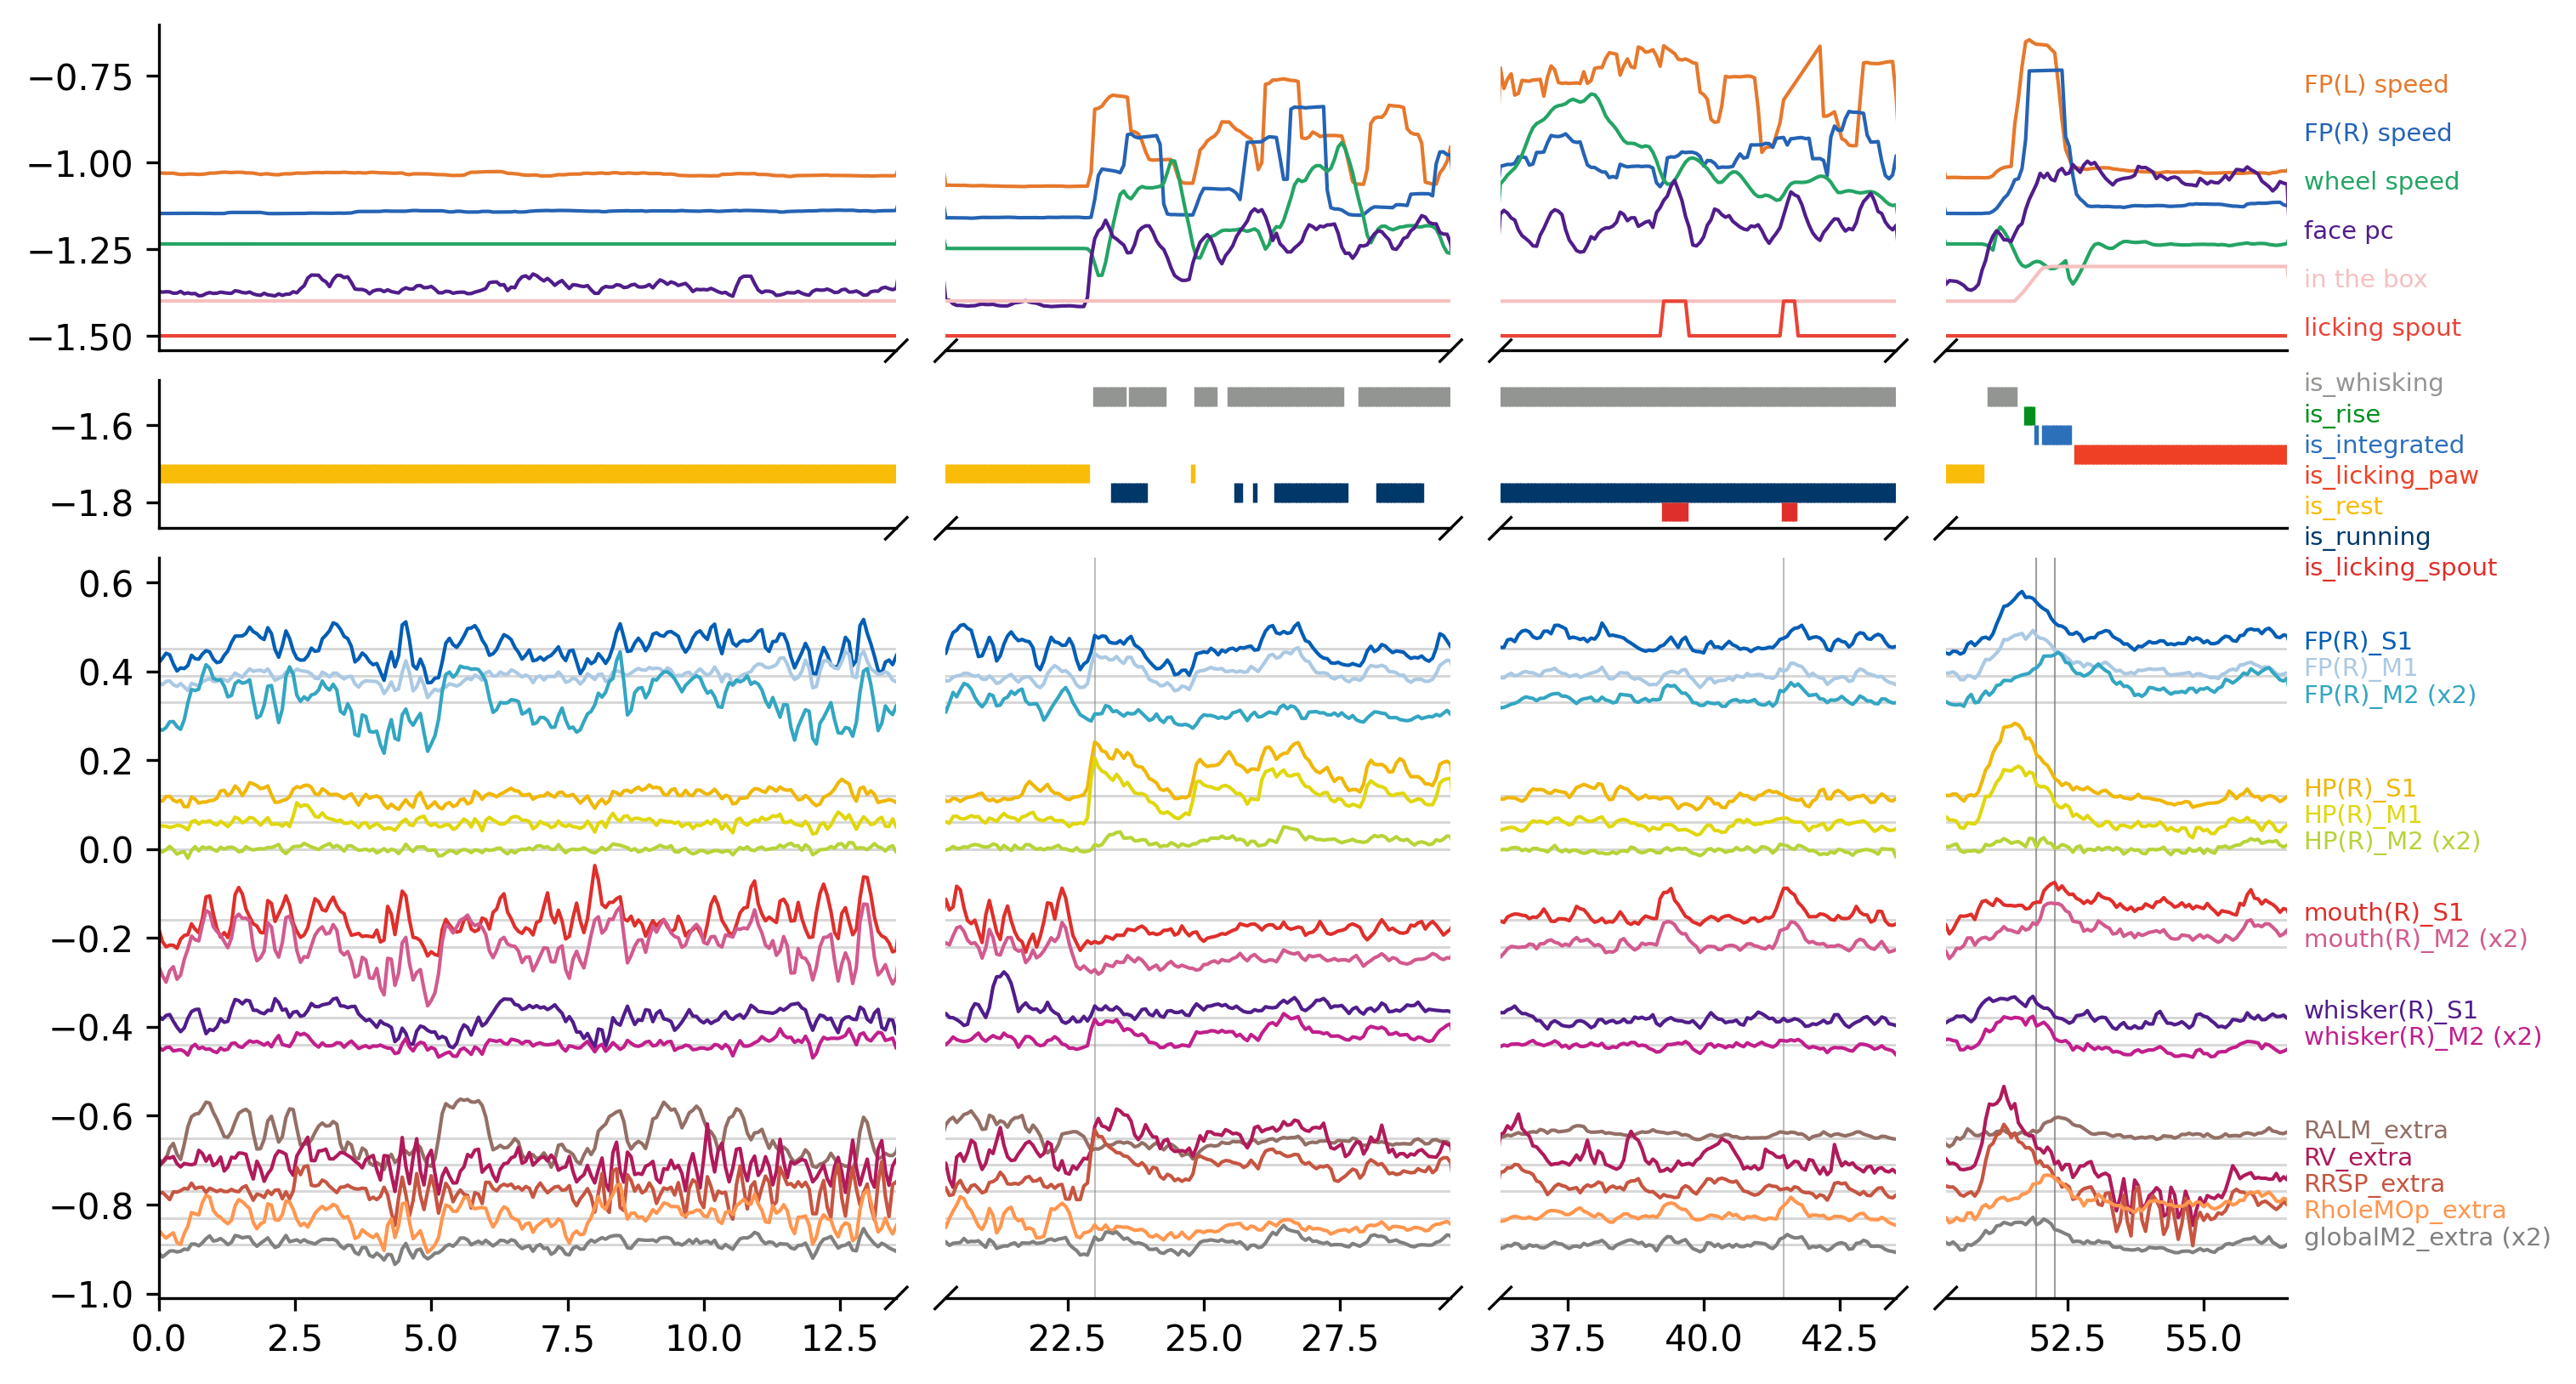

In [64]:
# t_ax_2show = np.divide(range(14000),15) #only show40 seconds
t_ax_2show = np.divide(range(cut_jrgeco.shape[-1]),15) #only show40 seconds
plt.style.use('default')
from brokenaxes import brokenaxes
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)
plt.subplots_adjust(hspace=1)

y_offset = 20;x_offset=20;
x_width=36;

x_start = x_offset
x_stop = x_start+x_width
# ax0 = fig.add_subplot(gs[y_offset-1:y_offset+5,x_start:x_stop])


gs0 = gs[y_offset-1:y_offset+5,x_start:x_stop]
gs1 = gs[y_offset+5:y_offset+8,x_start:x_stop]
gs2 = gs[y_offset+8:y_offset+21,x_start:x_stop]
# ax0 = fig.add_subplot(gs0)


    
# for i_choice_syllable, choice_syllable in enumerate(dict_select_time_range.keys()):
for i_ax in range(3):
    exec("gs_here = gs{}".format(i_ax))
    bar = brokenaxes(xlims=all_brokens,
            subplot_spec=gs_here,
                     fig=fig,
                     wspace=0.1,
                     d=0.002)
    exec("bar{} = bar".format(i_ax))
    if i_ax==0:
        for imoseq,moseq in enumerate(behaviors):
            bar0.plot(t_ax_2show,(behaviors[moseq][:]-1*imoseq)/10-1,color=palatte_behavior_fig7_dict[moseq],linewidth=1)
            bar0.axs[-1].text(all_brokens[-1][-1]+0.3,(-1.4*imoseq+0.02)/10-0.8,all_bev_short_dict[moseq],color=palatte_behavior_fig7_dict[moseq],fontsize=7)
    elif i_ax==1:
        # moseq
        for i, moseq in enumerate(['is_whisking', 'is_rise', 'is_integrated','is_licking_paw','is_rest','is_running' , 'is_licking_spout' ]):
            bar1.vlines(t_ax_2show[np.where(dict_moseq[moseq][:]==True)[0]], -1.5-i*0.05, -1.55-i*0.05,linewidth=1.3,color=palatte_moseq_dict[moseq])
            text_2_display = moseq
            bar1.axs[-1].text(all_brokens[-1][-1]+0.3,-1.51-i*0.08,'{}'.format(text_2_display),color=palatte_moseq_dict[moseq],fontsize=7)

    elif i_ax==2:
        for ii,bdp in enumerate(jrgeco2plot_NNLS):
            if bdp.split('_')[0] == 'RFP':
                offset_here = 0.45
            elif bdp.split('_')[0] == 'RHP':
                offset_here = 0.3
            elif bdp.split('_')[0] == 'RM':
                offset_here = 0.2
            elif bdp.split('_')[0] == 'RW':
                offset_here = 0.1
            elif bdp.split('_')[1] == 'extra':
                offset_here = -0.05          
                
            text_2_display = bdp.replace('RFP','FP(R)').replace('RM','mouth(R)').replace('RHP','HP(R)').replace('RW','whisker(R)')
            if bdp.split('_')[1]=='M2':
                bar2.plot(t_ax_2show,jrgeco2plot_NNLS[bdp][:]*2-0.06*ii+offset_here,color=palatte_dict[bdp],linewidth=1)
                text_2_display = text_2_display+' (x2)'
            elif bdp =='globalM2_extra':
                bar2.plot(t_ax_2show,jrgeco2plot_NNLS[bdp][:]*2-0.06*ii+offset_here,color=palatte_dict[bdp],linewidth=1)
                text_2_display = text_2_display+' (x2)'
            else:
                bar2.plot(t_ax_2show,jrgeco2plot_NNLS[bdp][:]-0.06*ii+offset_here,color=palatte_dict[bdp],linewidth=1)
            
            for i_small_ax in range(4):
                bar2.axs[i_small_ax].axhline(-0.06*ii+offset_here,linewidth = 0.7,color='lightgray',alpha=0.9,zorder=-9999)
            
            bar2.axs[-1].text(all_brokens[-1][-1]+0.3,-0.06*ii+offset_here,text_2_display,color=palatte_dict[bdp],fontsize=7)

    if i_ax<2:
        for ax in bar.axs:
            ax.set_xticks([])
        

for t_here in ind_collection['run']:
    bar2.axs[1].axvline(t_ax_2show[t_here],color='gray', alpha=0.5, zorder=-1000,linewidth=0.5)
for t_here in ind_collection['lick']:
    bar2.axs[2].axvline(t_ax_2show[t_here],color='gray',alpha=0.5, zorder=-1000,linewidth=0.5)
for t_here in ind_collection['integrated']:
    bar2.axs[3].axvline(t_ax_2show[t_here],color='gray', alpha=0.5, zorder=-1000,linewidth=0.5)
    bar2.axs[3].axvline(t_ax_2show[t_here],color='gray', alpha=0.5, zorder=-1000,linewidth=0.5)
    
    
# GRID
# # Set minor tick locations
# from matplotlib.ticker import MultipleLocator
# spacing = 0.05
# minorLocator = MultipleLocator(spacing)
# for i_ax in range(4):
#     bar2.axs[i_ax].yaxis.set_major_locator(minorLocator)
#     # Set grid to use minor tick locations. 
#     bar2.axs[i_ax].grid(axis='y',which = 'major',alpha=0.3)
     
        
        
plt.savefig('fig6-broken-TCs.svg',format='svg',dpi=300)



### check

### make highlights

In [518]:
webcam_root='/home/wx2203/hillman_servers/temp/hillman_servers/chronos/2/cmdata/'
day_label = 'cm229_9_runC'
day_name = day_label.split('_run')[0]
run_name = day_label.split(day_name)[1][1:]
ind = 4*(dict_select_time_range['integrated'][1]+500)
# img_fname_after = webcam_root+'{}/webcam/{}/*{}*cam0*'.format(day_name,run_name,int(ind)+4)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:5: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  """


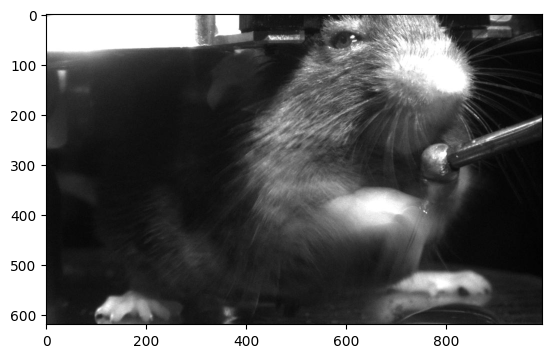

In [519]:
img_fname_before = webcam_root+'{}/webcam/{}/*_{}_*cam0*'.format(
    day_name,run_name,int(ind+15))

f1 = [f for f in glob.glob(img_fname_before, recursive=True)][0]
image_before = imageio.imread(f1)
plt.imshow(image_before[300:920,300:1292],cmap='gray')
dict_webcam_img['integrated_rise']= image_before[300:920,300:1292]

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:7: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  import sys


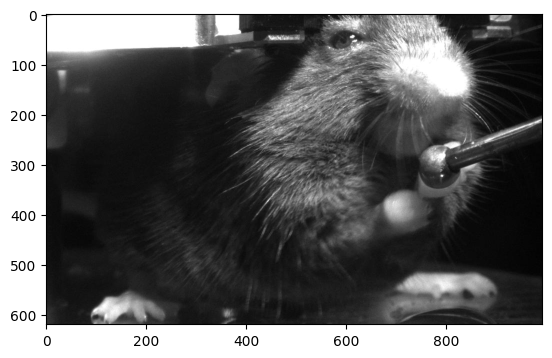

In [520]:
# img_fname_before = webcam_root+'{}/webcam/{}/*_{}_*cam0*'.format(
#     day_name,run_name,int(4*(3129+500)+3))
img_fname_before = webcam_root+'{}/webcam/{}/*_{}_*cam0*'.format(
    day_name,run_name,int(4*(3130+500)))

f1 = [f for f in glob.glob(img_fname_before, recursive=True)][0]
image_before = imageio.imread(f1)
plt.imshow(image_before[300:920,300:1292],cmap='gray')
dict_webcam_img['motif_lick_paw']= image_before[300:920,300:1292]

In [521]:
webcam_root='/home/wx2203/hillman_servers/temp/hillman_servers/chronos/2/cmdata/'
day_label = 'cm229_9_runD'
day_name = day_label.split('_run')[0]
run_name = day_label.split(day_name)[1][1:]
ind = 4*(dict_select_time_range['lick'][1]-total_tpt+500)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:7: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  import sys


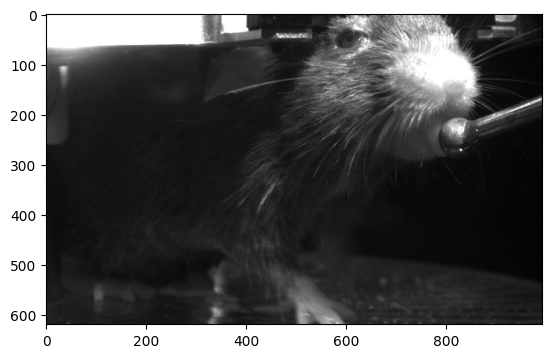

In [522]:
# img_fname_before = webcam_root+'{}/webcam/{}/*_{}_*cam0*'.format(
#     day_name,run_name,int(4*(3129+500)+3))
img_fname_before = webcam_root+'{}/webcam/{}/*_{}_*cam0*'.format(
    day_name,run_name,ind+3)

f1 = [f for f in glob.glob(img_fname_before, recursive=True)][0]
image_before = imageio.imread(f1)
plt.imshow(image_before[300:920,400:1392],cmap='gray')
dict_webcam_img['lick']= image_before[300:920,400:1392]

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:10: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  # Remove the CWD from sys.path while we load stuff.


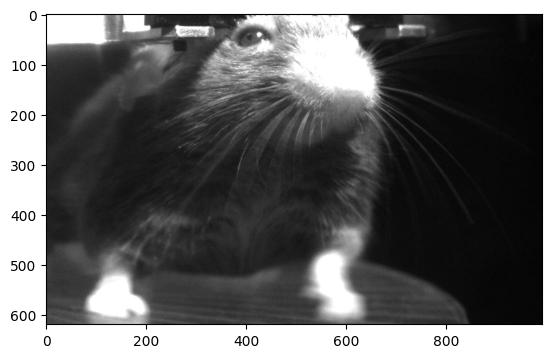

In [523]:
webcam_root='/home/wx2203/hillman_servers/temp/hillman_servers/chronos/2/cmdata/'
day_label = 'cm229_4_runB'
day_name = day_label.split('_run')[0]
run_name = day_label.split(day_name)[1][1:]
# img_fname_after = webcam_root+'{}/webcam/{}/*{}*cam0*'.format(day_name,run_name,int(ind)+4)
img_fname_before = webcam_root+'{}/webcam/{}/*_{}_*cam0*'.format(
    day_name,run_name,int(4*(4183+500)))

f2 = [f for f in glob.glob(img_fname_before, recursive=True)][0]
image_before = imageio.imread(f2)
# plt.imshow(image_before[300:1000,270:1390],cmap='gray')
plt.imshow(image_before[300:920,380:1372],cmap='gray')

dict_webcam_img['run']= image_before[300:920,380:1372]

#### plot neural map

integrated

In [65]:
# norm_factor_rest = concat_jrgeco[:,:,3100:3112]
# norm_factor_run = concat_jrgeco[:,:,3105+8:3105+21]
norm_factor_run = cut_jrgeco[:,:,new_time_range[-1][0]+8:new_time_range[-1][0]+24]
T=45
signal_here = cut_jrgeco[:,:,new_time_range[-1][0]:new_time_range[-1][0]+T]

signal_here_norm = signal_here - np.mean(norm_factor_run,2)[:,:,np.newaxis]
M_jrgeco_integrated_bslrun = signal_here_norm


In [66]:
dict_precise_timing={'move':range(8,21),'rise':range(25,26),'lick_paw':range(29,32)}

In [89]:
extra_bdp_color_dict = {
    'ALM-M2':palatte_dict['ALM'], 'RV-S1M1':palatte_dict['RV'],
                        'LV-S1M1':palatte_dict['RV'],'RSP-S1M1':palatte_dict['RSP'],
                        
                        'RALM':palatte_dict['ALM'],'LALM':palatte_dict['ALM'],
                        'RRSP':palatte_dict['RSP'],'LRSP':palatte_dict['RSP'],
                        
                  'RFP_M1_extra':palatte_dict['LFP'],
                        'LFP_M1_extra':palatte_dict['LFP'],
                'RholeMOp_extra' : '#ff964f', #pastel orange
                'LholeMOp_extra' : '#ff964f', #pastel orange
                       'median':'gray'}

In [71]:

M2_S1M1_contours = load_pickle(figure_config_root+'M2-S1M1_area_segment_'+mouse)['contours']


In [72]:
H_nnls = H_fitted

In [103]:
######################################################################
import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]
for bdp_w_label in extra_bdp_color_dict:
    dict_rgb_colors[bdp_w_label] = [mcolors.hex2color(extra_bdp_color_dict[bdp_w_label])]

SCALE_VALUE = 30

# Create the blended movie (avg time course)
T = H_nnls.shape[1]
blended_movie_integrated =  [] #= np.zeros((256, 256, 3,T), dtype=np.float32)

# Blend images with colors
for t in range(T):
    blended_image = np.zeros((256, 256, 3),dtype=np.float32)
    for i_M2, bdp in enumerate(['RFP', 'RHP', 'RW', 'RM', 'LFP', 'LHP', 'LW', 'LM']):
        color = dict_rgb_colors[bdp.replace('L','R')]
        ind_in_list = all_bdps_w_order.index(bdp+'_M2')
        image = W_masked[:,:,ind_in_list]
        H_nnls_bouts_avged = H_fitted[ind_in_list,:] * SCALE_VALUE # scale it up
        scaling = H_nnls_bouts_avged[t]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        blended_image += image_scaled[:, :, np.newaxis] * color
    
    for i_M2, bdp in enumerate(['RFP', 'RHP', 'RW', 'RM', 'LFP', 'LHP', 'LW', 'LM']):
        color = dict_rgb_colors[bdp.replace('L','R')]
        ind_in_list = all_bdps_w_order.index(bdp+'_S1')
        image = W_masked[:,:,ind_in_list]
        H_nnls_bouts_avged = H_fitted[ind_in_list,:] * SCALE_VALUE # scale it up
        scaling = H_nnls_bouts_avged[t]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        blended_image += image_scaled[:, :, np.newaxis] * color

    for i_M2, bdp in enumerate(['RFP', 'RHP', 'LFP', 'LHP']):
        color = dict_rgb_colors[bdp.replace('L','R')]
        ind_in_list = all_bdps_w_order.index(bdp+'_M1')
        image = W_masked[:,:,ind_in_list]
        H_nnls_bouts_avged = H_fitted[ind_in_list,:] * SCALE_VALUE # scale it up
        scaling = H_nnls_bouts_avged[t]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        blended_image += image_scaled[:, :, np.newaxis] * color
        
    # MOp hole
    for i_M2, bdp in enumerate(['RholeMOp','LholeMOp']):
        color = dict_rgb_colors[bdp+'_extra']
        ind_in_list = all_bdps_w_order.index(bdp)
        image = W_masked[:,:,ind_in_list]
        H_nnls_bouts_avged = H_nnls[ind_in_list,:] * SCALE_VALUE # scale it up
        scaling = H_nnls_bouts_avged[t]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        blended_image += image_scaled[:, :, np.newaxis] * color
    
    # # FORELIMB
    # for i_M2, bdp in enumerate(['RFP', 'LFP']):
    #     color = dict_rgb_colors[bdp+'_M1_extra']
    #     ind_in_list = all_bdps_w_order.index(bdp+'_M1_extra')
    #     image = W_masked_S1M2M1[:,:,ind_in_list]
    #     H_nnls_bouts_avged = H_nnls[ind_in_list,:] * SCALE_VALUE # scale it up
    #     scaling = H_nnls_bouts_avged[t]
    #     image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
    #     blended_image += image_scaled[:, :, np.newaxis] * color
    
    
    blended_movie_integrated.append(blended_image)
    
blended_movie_integrated = np.stack(blended_movie_integrated,axis=3)
# # Ensure values are within valid range
# blended_movie = np.clip(blended_movie, 0, 1)



In [104]:
blended_movie_integrated.shape

(256, 256, 3, 949)

In [105]:
norm_factor_run = blended_movie_integrated[:,:,:,new_time_range[-1][0]+8:new_time_range[-1][0]+24]
T=45
signal_here = blended_movie_integrated[:,:,:,new_time_range[-1][0]:new_time_range[-1][0]+T]

signal_here_norm = signal_here - np.mean(norm_factor_run,3)[:,:,:,np.newaxis]
blended_movie_integrated_bslrun = signal_here_norm

In [106]:
M_jrgeco_integrated_bslrun.shape

(256, 256, 45)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


(-0.5, 255.5, 255.5, -0.5)

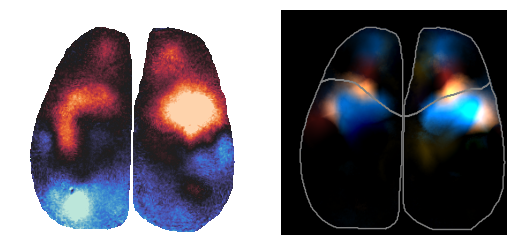

In [107]:
snapshot_integrated_rise = np.mean(M_jrgeco_integrated_bslrun[:,:,dict_precise_timing['rise']],-1)
snapshot_integrated_rise_blended = np.mean(blended_movie_integrated_bslrun[:,:,:,dict_precise_timing['rise']],-1)
# t=24
# snapshot_integrated = M_jrgeco_integrated_bslrun[:,:,t]
# snapshot_integrated_blended = blended_movie[:,:,:,t]

plt.subplot(121)
plt.imshow(snapshot_integrated_rise,vmin=-0.06,vmax=0.06,cmap='icefire')
plt.axis('off')
plt.subplot(122)
plt.imshow(snapshot_integrated_rise_blended)
for contour in M2_S1M1_contours['M2']:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.99)
for contour in M2_S1M1_contours['S1M1']:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.99)

plt.axis('off')

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


(-0.5, 255.5, 255.5, -0.5)

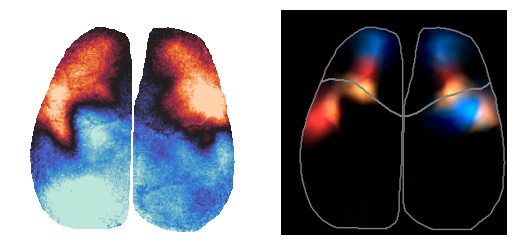

In [108]:
snapshot_integrated_lick_paws = np.mean(M_jrgeco_integrated_bslrun[:,:,dict_precise_timing['lick_paw']],-1)
snapshot_integrated_lick_paws_blended = np.mean(blended_movie_integrated_bslrun[:,:,:,dict_precise_timing['lick_paw']],-1)
# t=24
# snapshot_integrated = M_jrgeco_integrated_bslrun[:,:,t]
# snapshot_integrated_blended = blended_movie[:,:,:,t]

plt.subplot(121)
plt.imshow(snapshot_integrated_lick_paws,vmin=-0.06,vmax=0.06,cmap='icefire')
plt.axis('off')
plt.subplot(122)
plt.imshow(snapshot_integrated_lick_paws_blended)
for contour in M2_S1M1_contours['M2']:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.99)
for contour in M2_S1M1_contours['S1M1']:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.99)

plt.axis('off')

#### lick during run

In [110]:
ind_collection

{'run': [345], 'lick': [622], 'integrated': [779, 784]}

In [111]:
# norm_factor_rest = concat_jrgeco[:,:,3100:3112]
norm_factor_run = cut_jrgeco[:,:,ind_collection['lick'][0]-15:ind_collection['lick'][0]-4]
T=45;T_PRE = 35
signal_here = cut_jrgeco[:,:,ind_collection['lick'][0]-15:ind_collection['lick'][0]-15+T]

signal_here_norm = signal_here - np.mean(norm_factor_run,2)[:,:,np.newaxis]
M_jrgeco_lick_bslrun = signal_here_norm


In [112]:
norm_factor_run = blended_movie_integrated[:,:,:,ind_collection['lick'][0]-15:ind_collection['lick'][0]-4]
T=45
signal_here = blended_movie_integrated[:,:,:,ind_collection['lick'][0]-15:ind_collection['lick'][0]-15+T]

signal_here_norm = signal_here - np.mean(norm_factor_run,3)[:,:,:,np.newaxis]
blended_movie_lick_bslrun = signal_here_norm

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


(-0.5, 255.5, 255.5, -0.5)

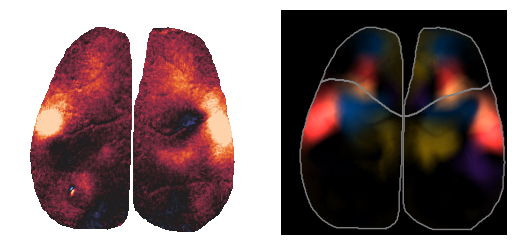

In [113]:
t=15
snapshot_lick = M_jrgeco_lick_bslrun[:,:,t]
snapshot_lick_blended = blended_movie_lick_bslrun[:,:,:,t]

plt.subplot(121)
plt.imshow(snapshot_lick,vmin=-0.05,vmax=0.05,cmap='icefire')
plt.axis('off')
plt.subplot(122)
plt.imshow(snapshot_lick_blended)
for contour in M2_S1M1_contours['M2']:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.99)
for contour in M2_S1M1_contours['S1M1']:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.99)

plt.axis('off')

### running

In [114]:
norm_factor_run = cut_jrgeco[:,:,ind_collection['run'][0]-10:ind_collection['run'][0]]
T=45;T_PRE = 35
signal_here = cut_jrgeco[:,:,ind_collection['run'][0]-35:ind_collection['run'][0]-35+T]

signal_here_norm = signal_here - np.mean(norm_factor_run,2)[:,:,np.newaxis]
M_jrgeco_run_bslrun = signal_here_norm
# NOW, fit NNLS

In [115]:
norm_factor_run = blended_movie_integrated[:,:,:,ind_collection['run'][0]-6:ind_collection['run'][0]]
T=45
signal_here = blended_movie_integrated[:,:,:,ind_collection['run'][0]-35:ind_collection['run'][0]-35+T]

signal_here_norm = signal_here - np.mean(norm_factor_run,3)[:,:,:,np.newaxis]
blended_movie_run_bslrest = signal_here_norm
blended_movie_run_bslrest = blended_movie_run_bslrest/1.2 # too bright



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


(-0.5, 255.5, 255.5, -0.5)

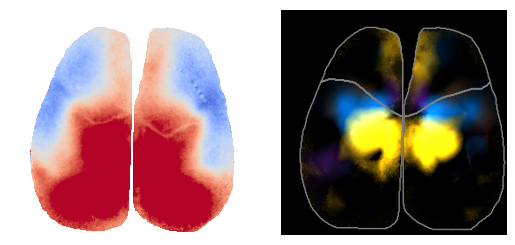

In [116]:
t=36
snapshot_run = M_jrgeco_run_bslrun[:,:,t]
snapshot_run_blended = blended_movie_run_bslrest[:,:,:,t]

plt.subplot(121)
plt.imshow(snapshot_run,vmin=-0.08,vmax=0.08,cmap='coolwarm')
plt.axis('off')
plt.subplot(122)
plt.imshow(snapshot_run_blended)
for contour in M2_S1M1_contours['M2']:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.99)
for contour in M2_S1M1_contours['S1M1']:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.99)

plt.axis('off')

#### now make figures

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


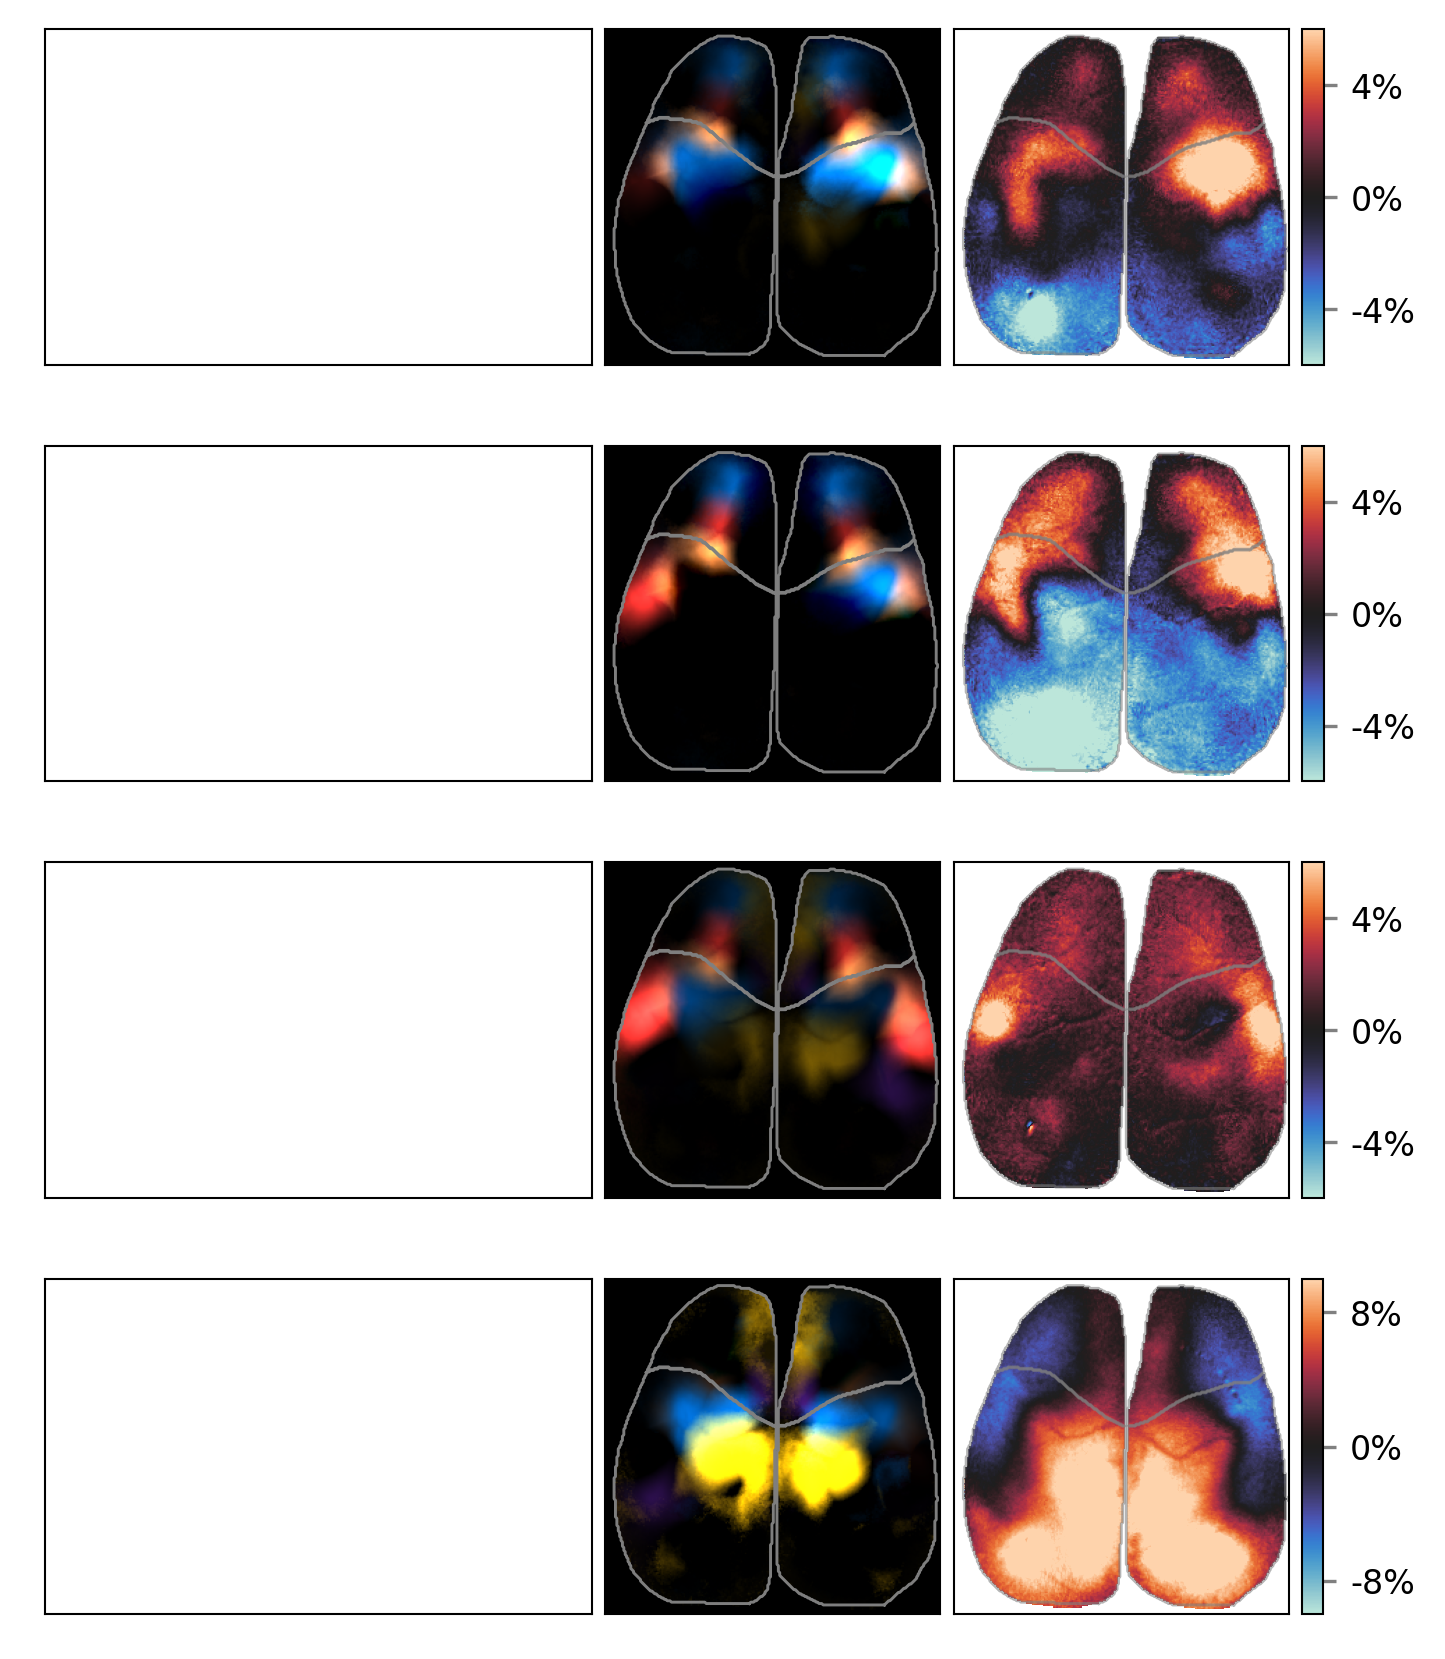

In [118]:
plt.style.use('default')
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)

# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

for i_count, beh in enumerate(['rise','lick_paws','lick','run']):
    # webcam image
    x_start = x_offset
    x_stop = x_start+8
    y_start = y_offset + 6*i_count
    y_stop = y_start + 5
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(0+3*i_count))
    x_start = x_stop
    x_stop = x_start+5
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(1+3*i_count))
    x_start = x_stop
    x_stop = x_start+5
    # jrgeco snapshots for 'run'''''
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(2+3*i_count))
    # colorbar for jrgeco snapshot
    x_start = x_stop
    x_stop = x_start+1
    exec("ax99{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(2+3*i_count))

###########
# #webcam
# ax0.imshow(dict_webcam_img['integrated_rise'],cmap='gray')
# ax3.imshow(dict_webcam_img['motif_lick_paw'],cmap='gray')
# ax6.imshow(dict_webcam_img['lick'],cmap='gray')
# ax9.imshow(dict_webcam_img['run'],cmap='gray')
# #blended
ax1.imshow(snapshot_integrated_rise_blended)
ax4.imshow(snapshot_integrated_lick_paws_blended)
ax7.imshow(snapshot_lick_blended)
ax10.imshow(snapshot_run_blended)
# neural DF/F
sbp2=ax2.imshow(snapshot_integrated_rise,vmin=-0.06,vmax=0.06,cmap='icefire')
sbp5=ax5.imshow(snapshot_integrated_lick_paws,vmin=-0.06,vmax=0.06,cmap='icefire')
sbp8=ax8.imshow(snapshot_lick,vmin=-0.06,vmax=0.06,cmap='icefire')
sbp11=ax11.imshow(snapshot_run,vmin=-0.1,vmax=0.1,cmap='icefire')
#colorbar
for ax_num in [2,5,8,11]:
    exec("cb = fig.colorbar(sbp{}, cax=ax99{},fraction=0.2,orientation='vertical',format=FuncFormatter(fmt));".format(ax_num,ax_num))
    cb.ax.tick_params(labelsize=8,length=3,color='gray')
    cb.ax.yaxis.tick_right()       
    cb.outline.set_edgecolor('black')
    cb.outline.set_linewidth(0.5)
    tick_locator = ticker.MaxNLocator(nbins=3)
    cb.locator = tick_locator
    cb.update_ticks()
    if ax_num==11:
        exec("ax99{}.set_aspect(80)".format(ax_num))
    else:
        exec("ax99{}.set_aspect(130)".format(ax_num))
    exec("ax99{}.set_anchor('W')".format(ax_num))
    
for i_ax in [1,4,7,10]:
    for contour in M2_S1M1_contours['M2']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.7,color='gray',alpha=0.99)".format(i_ax))
    for contour in M2_S1M1_contours['S1M1']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.7,color='gray',alpha=0.99)".format(i_ax))
for i_ax in [2,5,8,11]:
    for contour in M2_S1M1_contours['M2']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.7,color='gray',alpha=0.59)".format(i_ax))
    for contour in M2_S1M1_contours['S1M1']:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.7,color='gray',alpha=0.59)".format(i_ax))

########### setting 
for i_ax in [1,4,7,10,2,5,8,11]:
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    
for axis in ['top','right','left','bottom']:
    for i_ax in range(0,20):
        try:
            exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
        except:
            continue
for i_ax in range(0,20):
    try:
        exec("ax{}.set_xticks([])".format(i_ax))
        exec("ax{}.set_yticks([])".format(i_ax))
    except:
        continue
        
plt.savefig('fig6-webcam-blended-neural.svg',format='svg',dpi=300)

# DONE

# piece together

In [537]:
import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]
for bdp_w_label in extra_bdp_color_dict:
    dict_rgb_colors[bdp_w_label] = [mcolors.hex2color(extra_bdp_color_dict[bdp_w_label])]

dict_rgb_colors['LV']=dict_rgb_colors['RV']
# dict_rgb_colors['RV']=dict_rgb_colors['RV-S1M1']


scaling = 1.3
mask_3 = np.repeat(mask[:,:,np.newaxis],repeats=3,axis=-1)
mask_3[mask_3==1]=0
mask_3 = np.nan_to_num(mask_3.copy(),nan=scaling)

dict_blended_brain_maps =  {}

for area in ['M2','M1','S1']:
    blended_image = np.zeros((256, 256, 3),dtype=np.float32)
    for i_M2, bdp in enumerate(['RFP', 'RHP', 'RM', 'RW','LFP', 'LHP', 'LM','LW']):
        color = dict_rgb_colors[bdp.replace('L','R')]
        ind_in_list = all_bdps.index(bdp+'_'+area)
        image = W_masked[:,:,ind_in_list]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        blended_image += image_scaled[:, :, np.newaxis] * color
    dict_blended_brain_maps[area] = mask_3+blended_image

for bdp_extra in ['RFP_M1_extra', 'LFP_M1_extra']:
    color = dict_rgb_colors[bdp_extra.replace('L','R')]
    ind_in_list = all_bdps.index(bdp_extra)
    image = W_masked[:,:,ind_in_list]
    image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
    dict_blended_brain_maps['S1'] += mask_3+image_scaled[:, :, np.newaxis] * color

blended_image = np.zeros((256, 256, 3),dtype=np.float32)
for i_key,key in enumerate(['RALM', 'LALM', 'RV', 'LV', 'RRSP', 'LRSP']):
    ind_in_list = all_bdps.index(key)
    color = dict_rgb_colors[key]
    image = W_masked[:,:,ind_in_list]
    image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
    blended_image += image_scaled[:, :, np.newaxis] * color
    
ind_in_list = -2 # global M2
color = dict_rgb_colors['globalM2_extra']
image = W_masked[:,:,ind_in_list]
image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
blended_image += image_scaled[:, :, np.newaxis] * color
    
dict_blended_brain_maps['extra'] = mask_3+blended_image


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


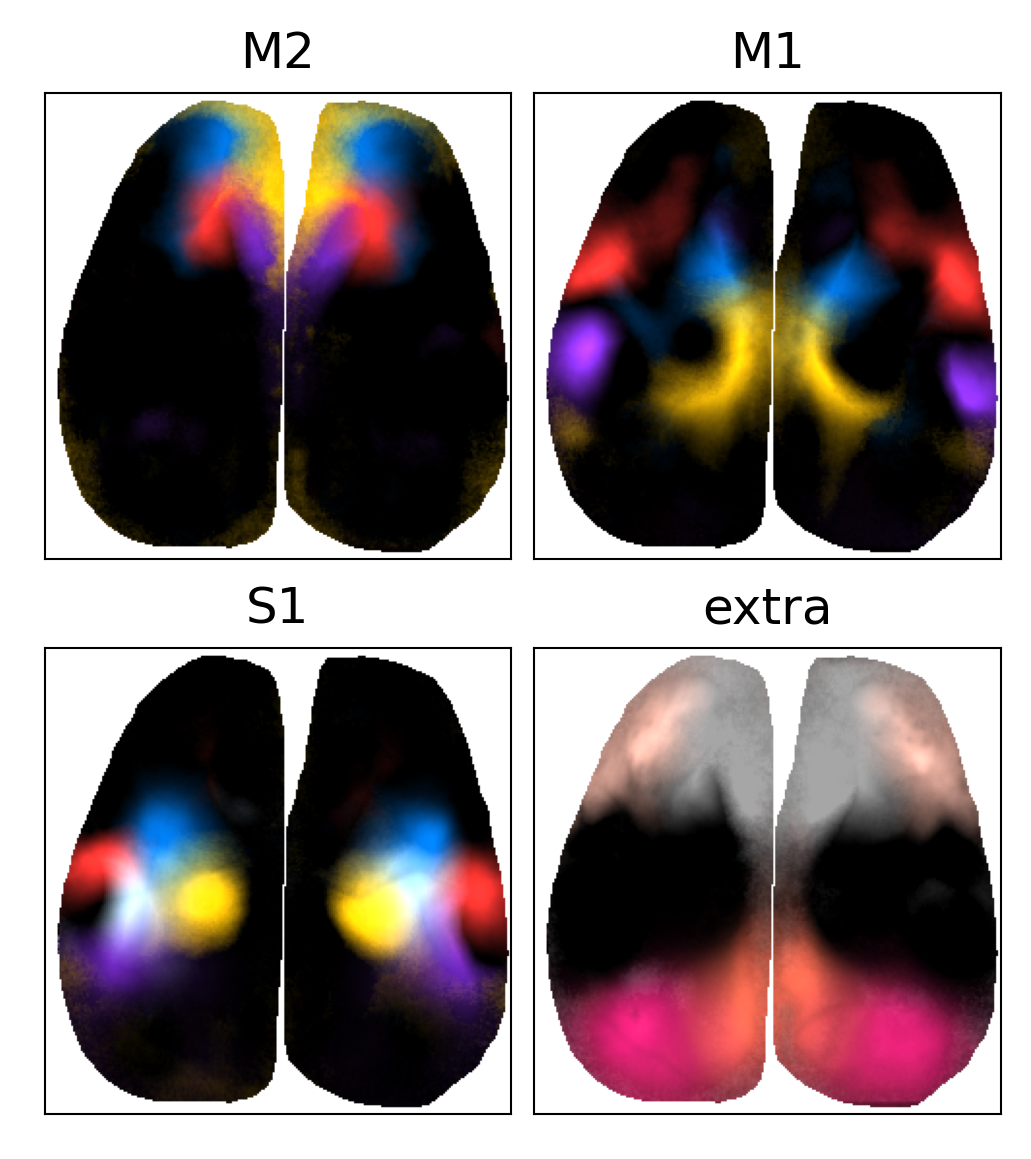

In [539]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = x_offset
x_stop = x_start+7
for i_ax in range(2):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+7,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+7
    
x_start = x_offset
x_stop = x_start+7
for i_ax in range(2,4):
    exec("ax{} = fig.add_subplot(gs[y_offset+8:y_offset+15,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+7
    

for i_ax, area in enumerate(['M2','M1','S1','extra']):
    exec("ax{}.imshow(dict_blended_brain_maps[area])".format(i_ax))
    exec("ax{}.set_title(area)".format(i_ax))
         
for i_part,part in enumerate(['top','bottom','left','right']):
    for i_ax in range(10):
        try:
            exec("ax{}.spines[part].set_linewidth(0.5) ".format(i_ax))
        except:
            continue  
plt.subplots_adjust(wspace=0.5)
plt.savefig('fig6-NNLS-pieced-together.svg',format='svg',dpi=300) 

# now, make key

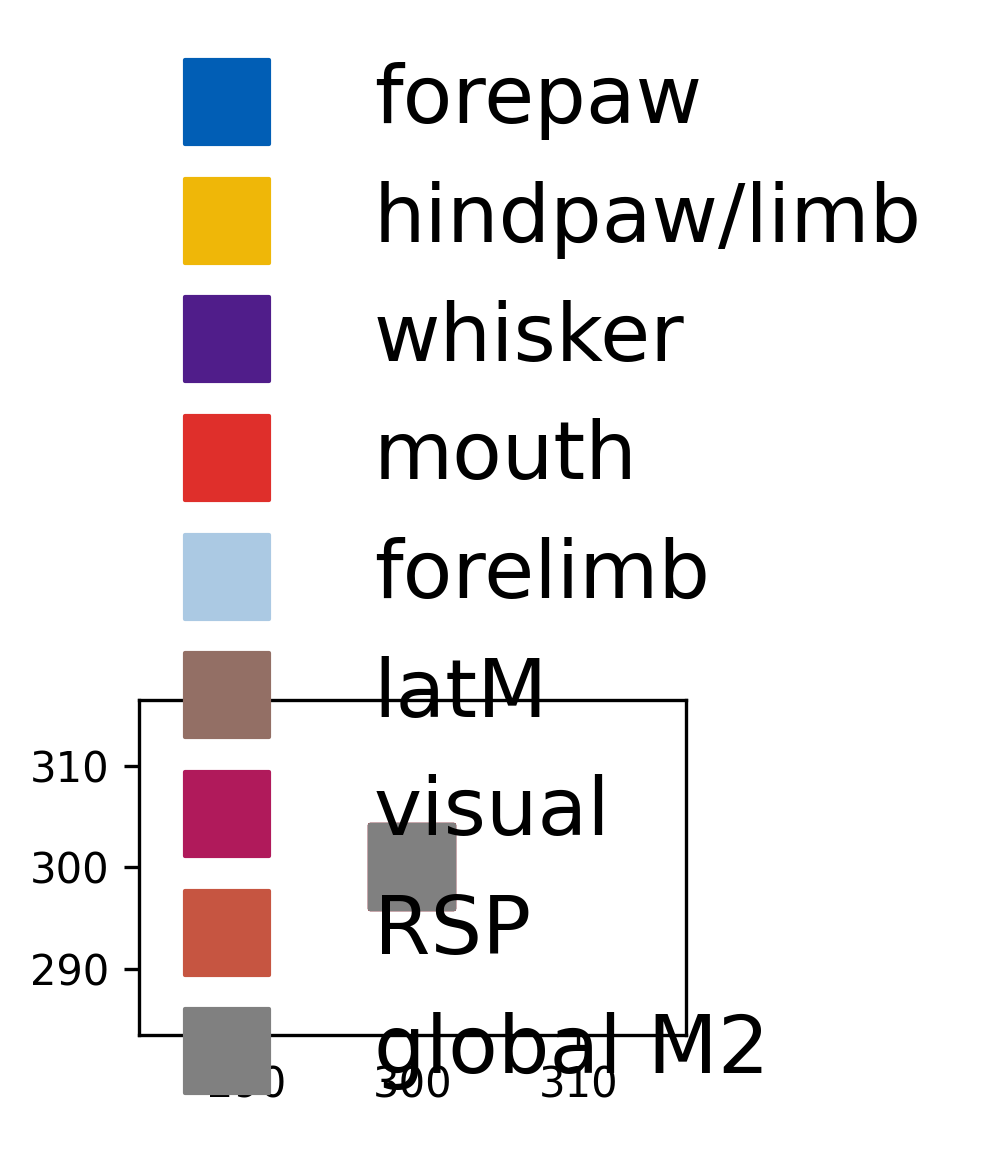

In [546]:
plt.style.use('default')
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)

# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

# webcam image
x_start = x_offset
x_stop = x_start+8
y_start = y_offset + 6*i_count
y_stop = y_start + 5
ax1 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])
    
    
bdp_short_dict = {'RFP':'forepaw','RHP':'hindpaw/limb','RM':'mouth',
                  'RW':'whisker','RFP_M1_extra':'forelimb','RALM_extra':'latM',
                 'RV_extra':'visual','RRSP_extra':'RSP','globalM2_extra':'global M2'}
palatte_dict['RFP_M1_extra']=palatte_dict['LFP']
for bdp in ['RFP','RHP','RW','RM','RFP_M1_extra','RALM_extra','RV_extra','RRSP_extra','globalM2_extra',]:
    ax1.scatter(300,300,label=bdp_short_dict[bdp],marker='s',s=400,color=palatte_dict[bdp])
ax1.legend(bbox_to_anchor=(-0.12,-0.38), loc="lower left", frameon=False,
                # bbox_transform=fig.transFigure,
           ncol=1,fontsize=19.5)

plt.savefig('fig6-legend.svg',format='svg',dpi=300)

# Key #2

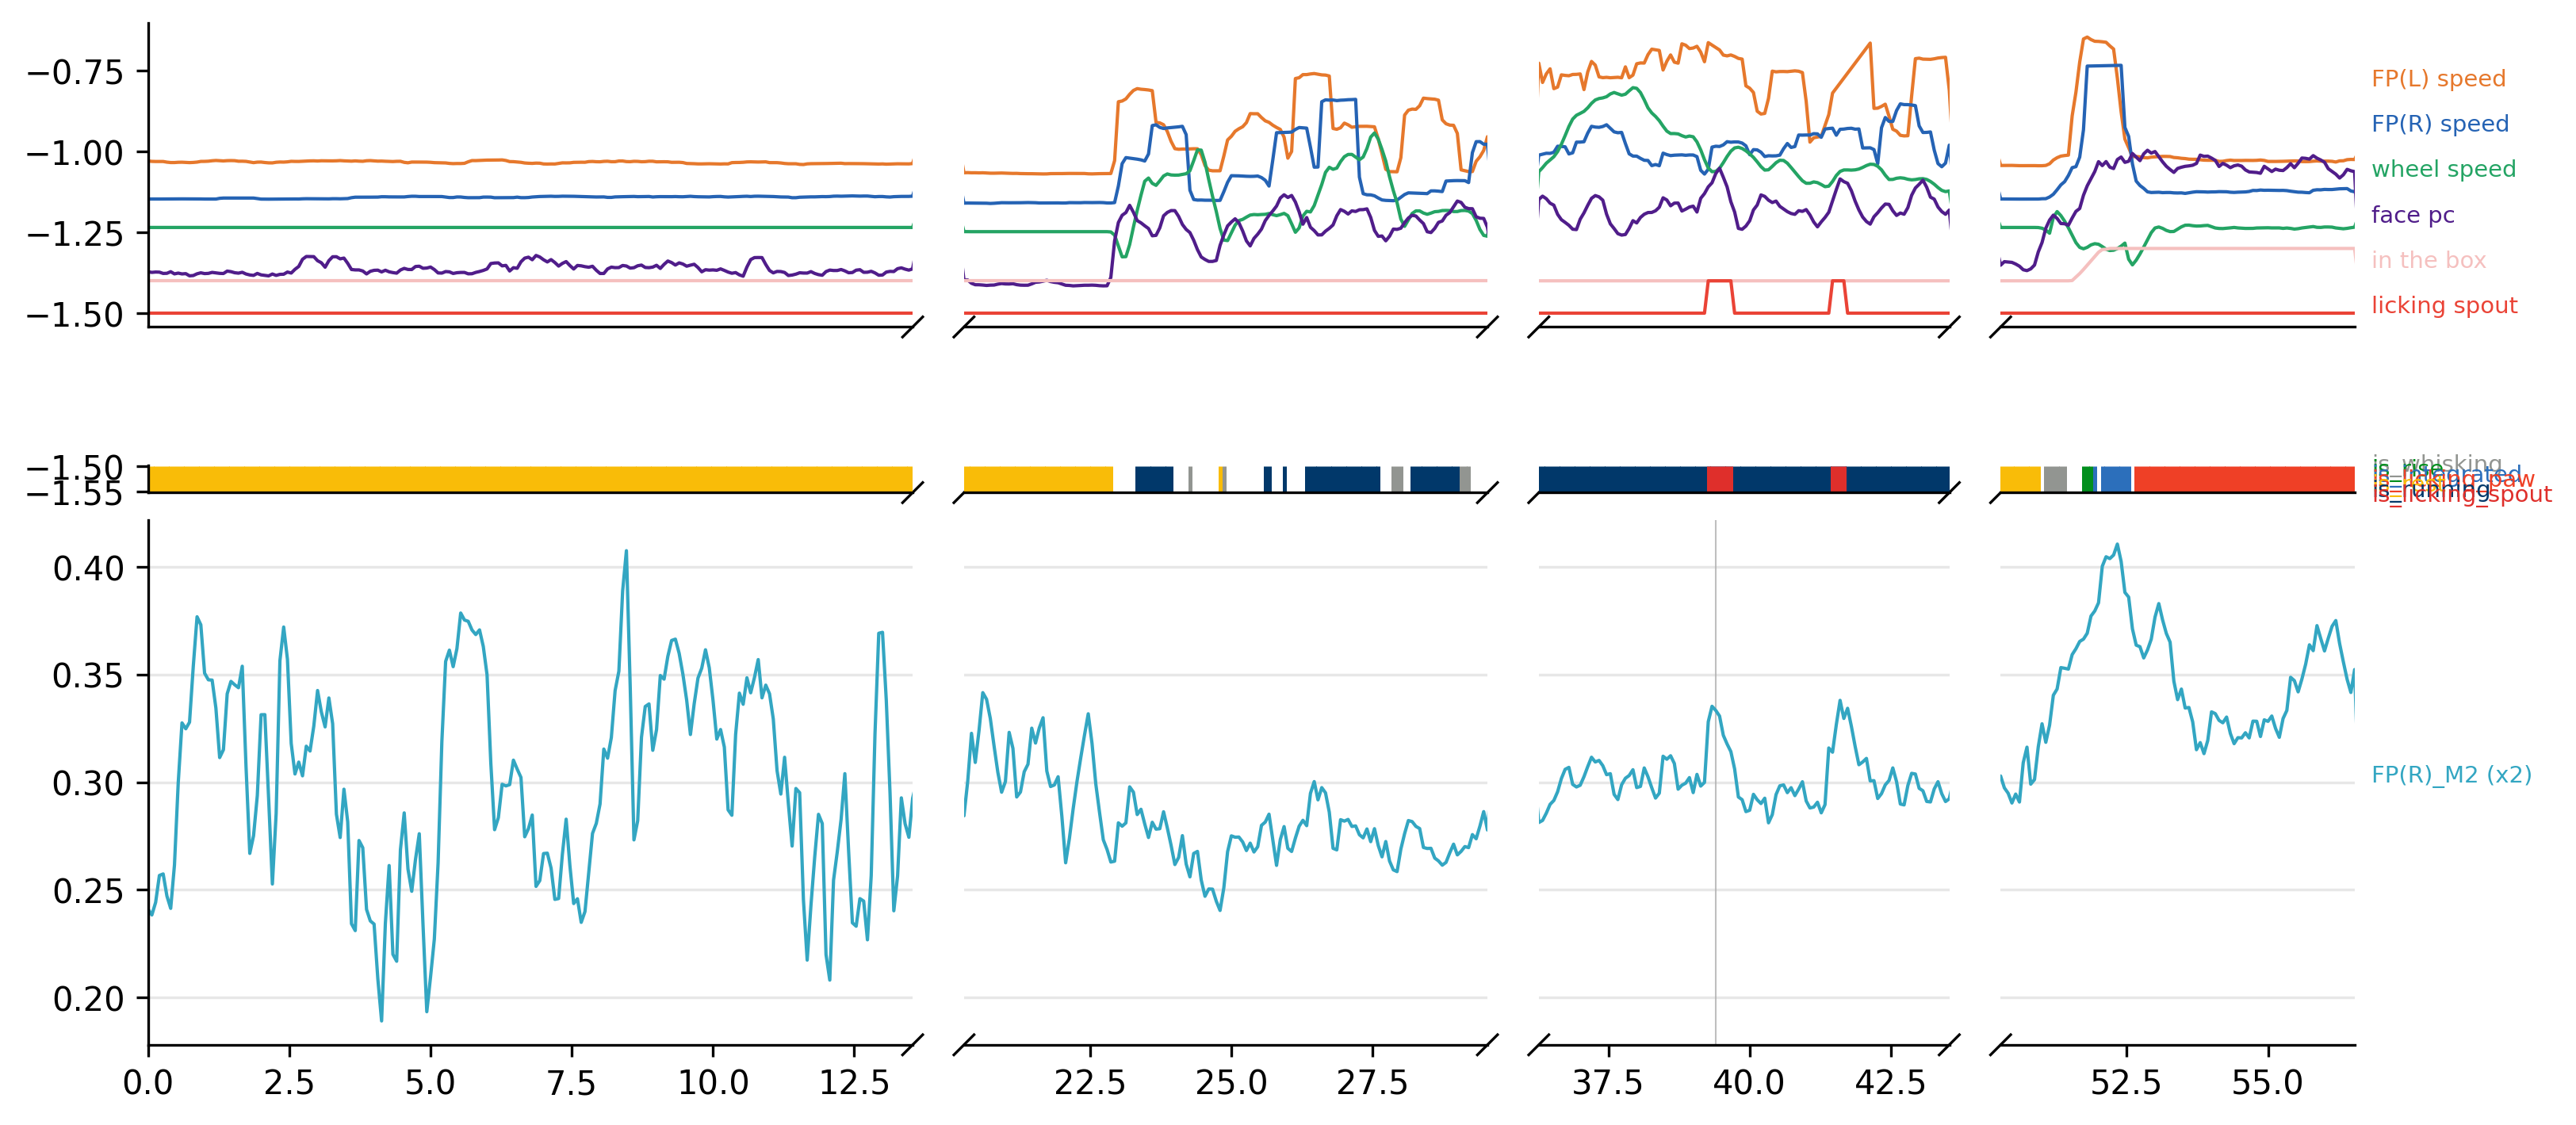

In [ ]:

t_ax_2show = np.divide(range(cut_jrgeco.shape[-1]),15) #only show40 seconds
plt.style.use('default')
from brokenaxes import brokenaxes
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)
plt.subplots_adjust(hspace=1)

y_offset = 20;x_offset=20;
x_width=40;

x_start = x_offset
x_stop = x_start+x_width
# ax0 = fig.add_subplot(gs[y_offset-1:y_offset+5,x_start:x_stop])


gs0 = gs[y_offset-1:y_offset+5,x_start:x_stop]
gs1 = gs[y_offset+7:y_offset+8,x_start:x_stop]
gs2 = gs[y_offset+8:y_offset+18,x_start:x_stop]
# ax0 = fig.add_subplot(gs0)


    
# for i_choice_syllable, choice_syllable in enumerate(dict_select_time_range.keys()):
for i_ax in range(3):
    exec("gs_here = gs{}".format(i_ax))
    bar = brokenaxes(xlims=all_brokens,
            subplot_spec=gs_here,
                     fig=fig,
                     wspace=0.1,
                     d=0.002)
    exec("bar{} = bar".format(i_ax))
    if i_ax==0:
        for imoseq,moseq in enumerate(behaviors):
            bar0.plot(t_ax_2show,(behaviors[moseq][:]-1*imoseq)/10-1,color=palatte_behavior_fig7_dict[moseq],linewidth=1)
            bar0.axs[-1].text(all_brokens[-1][-1]+0.3,(-1.4*imoseq+0.02)/10-0.8,all_bev_short_dict[moseq],color=palatte_behavior_fig7_dict[moseq],fontsize=7)
    elif i_ax==1:
        # moseq
        for i, moseq in enumerate(['is_whisking', 'is_rise', 'is_integrated','is_licking_paw','is_rest','is_running' , 'is_licking_spout' ]):
            bar1.vlines(t_ax_2show[np.where(dict_moseq[moseq][:]==True)[0]], -1.5-i*0.0, -1.55-i*0.0,linewidth=1.2,color=palatte_moseq_dict[moseq])
            text_2_display = moseq
            bar1.axs[-1].text(all_brokens[-1][-1]+0.3,-1.51-i*0.01,'{}'.format(text_2_display),color=palatte_moseq_dict[moseq],fontsize=7)

    elif i_ax==2:
        for ii,bdp in enumerate(['RFP_M2']):
            if bdp.split('_')[0] == 'RFP':
                offset_here = 0.3
            elif bdp.split('_')[0] == 'RHP':
                offset_here = 0.2
            elif bdp.split('_')[0] == 'RM':
                offset_here = 0.1
            elif bdp.split('_')[0] == 'RW':
                offset_here = 0
            
            text_2_display = bdp.replace('RFP','FP(R)').replace('RM','mouth(R)').replace('RHP','HP(R)').replace('RW','whisker(R)')
            if bdp.split('_')[1]=='M2':
                bar2.plot(t_ax_2show,jrgeco2plot_NNLS[bdp][:]*2-0.05*ii+offset_here,color=palatte_dict[bdp],linewidth=1)
                text_2_display = text_2_display+' (x2)'
            # elif bdp.split('_')[1]=='allM2':
            #     bar2.plot(t_ax_2show,jrgeco2plot_NNLS[bdp][:23920]-0.05*ii+offset_here,color=palatte_dict[bdp],linewidth=1)
            else:
                bar2.plot(t_ax_2show,jrgeco2plot_NNLS[bdp][:]-0.05*ii+offset_here,color=palatte_dict[bdp],linewidth=1)
            
            bar2.axs[-1].text(all_brokens[-1][-1]+0.3,-0.05*ii+offset_here,text_2_display,color=palatte_dict[bdp],fontsize=7)

    if i_ax<2:
        for ax in bar.axs:
            ax.set_xticks([])
        

for t_here in ind_collection['run']:
    bar2.axs[3].axvline(t_ax_2show[t_here],color='gray', alpha=0.5, zorder=-1000,linewidth=0.5)
for t_here in ind_collection['lick']:
    bar2.axs[2].axvline(t_ax_2show[t_here],color='gray',alpha=0.5, zorder=-1000,linewidth=0.5)
for t_here in ind_collection['integrated']:
    bar2.axs[1].axvline(t_ax_2show[t_here],color='gray', alpha=0.5, zorder=-1000,linewidth=0.5)
    bar2.axs[1].axvline(t_ax_2show[t_here],color='gray', alpha=0.5, zorder=-1000,linewidth=0.5)
    
# Set minor tick locations
from matplotlib.ticker import MultipleLocator
spacing = 0.05
minorLocator = MultipleLocator(spacing)
for i_ax in range(4):
    bar2.axs[i_ax].yaxis.set_major_locator(minorLocator)
    # Set grid to use minor tick locations. 
    bar2.axs[i_ax].grid(axis='y',which = 'major',alpha=0.3)
     
plt.savefig('fig6-key-2.svg',format='svg',dpi=300)

